# Multi-Class Classification of Haematological Patterns from Complete Blood Count (CBC) Data
### A Leakage-Controlled, Reproducible Machine-Learning and Deep-Learning Benchmark

**Authors:** Al Amin Remon, Mayen Uddin Mojumdar, Md. Sadekur Rahman — Department of Computer Science and Engineering, Daffodil International University

---
**Purpose.** This notebook reproduces every table and figure of the study. It benchmarks classical machine-learning,
ensemble and deep tabular models for five-class classification of CBC records and reports the results with
uncertainty estimates and sensitivity analyses.

**Evaluation design (summary).**

1. A stratified 80/20 train/test split is created *before* any preprocessing. The test set is withheld from
   preprocessing, model selection and hyper-parameter optimisation, and is used only for the final held-out
   evaluation and for the pre-specified secondary analyses that follow it (bootstrap intervals, calibration,
   sensitivity analyses, interpretation).
2. Imputation, scaling and oversampling are fitted only on training data (inside every cross-validation fold).
3. Model development uses stratified five-fold cross-validation within the training set. Hyper-parameters of the
   three best tunable models are optimised with Optuna on the same training data.
4. Every analysis that touches the test set is labelled as *post-hoc* or *secondary* and was not used to choose a model.

**Reporting note.** The class labels are CBC-pattern categories. Results describe how well the categories can be
recovered from CBC parameters; they are not estimates of diagnostic accuracy in a clinical population.

## 0. Environment Setup and Reproducibility

In [1]:
# ---- Optional installs (Kaggle already ships most of these). Uncomment if a package is missing. ----
# !pip -q install lightgbm xgboost catboost imbalanced-learn shap optuna pytorch-tabnet scikit-posthocs statsmodels

import os, sys, json, math, time, warnings, random, platform
os.environ["PYTHONWARNINGS"] = "ignore"          # also silences joblib/loky worker processes
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# ------------------------------------------------------------------------------------------------
# Global configuration
# ------------------------------------------------------------------------------------------------
SEED = 42
FAST_DEBUG = False          # Reduced-scale configuration for verifying that the pipeline executes end to end.
                            # Set to False (default) to reproduce the results and figures reported in the paper.
N_TRIALS   = 5 if FAST_DEBUG else 30     # Optuna trials per tuned model
N_BOOT     = 50 if FAST_DEBUG else 1000  # bootstrap resamples for confidence intervals
DL_EPOCHS  = 3 if FAST_DEBUG else 100    # maximum epochs for the deep models
USE_MISSING_INDICATORS = True            # median imputation with missing-indicator flags; fit inside every
                                          # cross-validation fold (Section 4), so the flags carry no leakage

random.seed(SEED)
np.random.seed(SEED)

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "figure.autolayout": True,
})
sns.set_palette("colorblind")

from pathlib import Path
ON_KAGGLE = os.path.exists("/kaggle")
# Repository root = the nearest parent folder that contains data/hematology_cbc_dataset.csv (works from notebooks/ or the root).
_HERE = Path.cwd().resolve()
REPO_ROOT = next((p for p in [_HERE, *_HERE.parents] if (p / "data" / "hematology_cbc_dataset.csv").exists()), _HERE)
# Outside Kaggle the notebook writes to results/notebook_run/ (git-ignored) so the committed results/ are never overwritten.
OUT_DIR   = "/kaggle/working/outputs" if ON_KAGGLE else str(REPO_ROOT / "results" / "notebook_run")
FIG_DIR   = os.path.join(OUT_DIR, "figures")
TAB_DIR   = os.path.join(OUT_DIR, "tables")
MODEL_DIR = os.path.join(OUT_DIR, "models")
for d in [OUT_DIR, FIG_DIR, TAB_DIR, MODEL_DIR]:
    os.makedirs(d, exist_ok=True)

try:
    import torch
    TORCH_OK = True
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
except ImportError:
    TORCH_OK = False
    device = "cpu"

print("Python", platform.python_version(), "| output directory:", OUT_DIR)
print("PyTorch available:", TORCH_OK, "| device:", device, "| FAST_DEBUG:", FAST_DEBUG)

Python 3.13.16 | output directory: /kaggle/working/outputs
PyTorch available: True | device: cuda | FAST_DEBUG: False


## 1. Load Data

The loader searches a few conventional locations so that the notebook runs unchanged on Kaggle or locally.
Column names are standardised (spelling and unit-explicit names) without altering any value.

In [2]:
import os
import glob
import pandas as pd

CANDIDATE_PATHS = [
    str(REPO_ROOT / "data" / "hematology_cbc_dataset.csv"),   # this repository
    "/kaggle/input/datasets/alaminremon/hematology-cbc-dataset/HEMATOLOGY_PRIMARY.csv",
    "./HEMATOLOGY_PRIMARY.csv",
    "./data/HEMATOLOGY_PRIMARY.csv",
]

DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)

if DATA_PATH is None:
    hits = glob.glob("/kaggle/input/**/*ematolog*.csv", recursive=True)
    DATA_PATH = hits[0] if hits else None

if DATA_PATH is None:
    raise FileNotFoundError("CSV not found. Attach the dataset or edit CANDIDATE_PATHS.")

df_raw = pd.read_csv(DATA_PATH)

# Standardise column names only (no value is changed).
RENAME = {
    "Lymphoeyte %": "Lymphocyte %",
    "platelat": "Platelet",
    "mpv": "MPV",
    "rETICULOCYTE": "Reticulocyte",
    "Neutrophil": "Neutrophil count",
    "Lymphocyte": "Lymphocyte count",
    "Monocyte": "Monocyte count",
    "Eosinophil": "Eosinophil count",
    "Basophil": "Basophil count",
}

df_raw = df_raw.rename(
    columns={k: v for k, v in RENAME.items() if k in df_raw.columns}
)

TARGET_COL = "Disorder_Class"

ABS_DIFF = [
    c for c in [
        "Neutrophil count", "Lymphocyte count", "Monocyte count",
        "Eosinophil count", "Basophil count"
    ] if c in df_raw.columns
]

PCT_DIFF = [
    c for c in [
        "Neutrophil %", "Lymphocyte %", "Monocyte %",
        "Eosinophil %", "Basophil %"
    ] if c in df_raw.columns
]

print("Dataset file:", os.path.basename(DATA_PATH), "| shape:", df_raw.shape)
df_raw.head()

Dataset file: hematology_cbc_dataset.csv | shape: (12618, 24)


,WBC,Neutrophil count,Lymphocyte count,Monocyte count,Eosinophil count,Basophil count,Neutrophil %,Lymphocyte %,Monocyte %,Eosinophil %,...,MCV,MCH,MCHC,RDW,Platelet,MPV,PCT,PDW,ESR,Disorder_Class
0,12.12,6.90,3.03,0.30,0.15,1.74,56.90,25.00,2.50,1.30,...,70.51,21.65,30.71,15.46,317.26,13.23,0.42,10.76,59.030000,Microcytic Hypochromic Anaemia
1,10.30,6.74,2.08,0.25,0.08,1.14,65.40,20.20,NaN,0.80,...,71.89,25.02,34.81,20.17,256.73,10.43,0.27,12.56,52.000000,Microcytic Hypochromic Anaemia
2,5.00,3.92,0.91,0.07,0.07,0.02,78.50,18.10,1.50,1.50,...,95.97,30.63,31.92,16.62,284.15,9.56,0.27,12.49,55.842850,Normal / Non-specific
3,4.02,2.36,1.32,0.18,0.05,0.11,59.39,32.25,4.42,1.28,...,70.80,25.98,36.69,17.11,277.66,12.30,0.34,14.46,36.020000,Microcytic Hypochromic Anaemia
4,13.79,10.14,2.50,0.27,0.21,0.68,73.50,18.10,2.00,1.50,...,84.10,31.39,37.32,14.10,165.40,10.53,0.17,13.91,42.734027,Mild-Moderate Leukocytosis


## 2. Data Description and Quality Audit

These checks document the dataset before modelling. They are descriptive: they establish which columns are usable,
whether any non-biological column (such as a record serial number) carries class information, how internally
consistent the CBC parameters are, and how strongly individual features are tied to the class definitions.

In [3]:
# ---- 2.1 Non-feature (identifier-like) columns ----
ID_NAMES = {"s", "id", "sl", "sl.", "sno", "s.no", "serial", "index", "patient_id", "patientid", "mrn"}
ID_COLS = [c for c in df_raw.columns
           if c != TARGET_COL and (c.strip().lower() in ID_NAMES or c.strip().lower().endswith("_id"))]
print("Identifier-like columns excluded from the feature set:", ID_COLS)

# ---- Audit: does the record serial number carry class information? ----
from scipy.stats import kruskal
from sklearn.metrics import roc_auc_score
serial_rows = []
for c in ID_COLS:
    if pd.api.types.is_numeric_dtype(df_raw[c]):
        groups = [g[c].dropna().values for _, g in df_raw.groupby(TARGET_COL)]
        h, p = kruskal(*groups)
        aucs = {cls: max(roc_auc_score((df_raw[TARGET_COL] == cls).astype(int), df_raw[c].fillna(df_raw[c].median())),
                          1 - roc_auc_score((df_raw[TARGET_COL] == cls).astype(int), df_raw[c].fillna(df_raw[c].median())))
                for cls in df_raw[TARGET_COL].unique()}
        serial_rows.append({"Column": c, "Kruskal_H": round(h, 3), "Kruskal_p": p,
                            "Max_single_class_AUC": round(max(aucs.values()), 4)})
serial_audit_df = pd.DataFrame(serial_rows)
if len(serial_audit_df):
    serial_audit_df.to_csv(os.path.join(TAB_DIR, "TableS1_identifier_audit.csv"), index=False)
serial_audit_df

Identifier-like columns excluded from the feature set: []


""


In [4]:
# ---- 2.2 Class distribution (Table 1) ----
class_counts = df_raw[TARGET_COL].value_counts()
table1 = pd.DataFrame({"Count": class_counts, "Percent": (class_counts / len(df_raw) * 100).round(2)})
table1.to_csv(os.path.join(TAB_DIR, "Table1_class_distribution.csv"))
table1

,Count,Percent
Disorder_Class,,
Microcytic Hypochromic Anaemia,2994,23.73
Normal / Non-specific,2541,20.14
Mild-Moderate Leukocytosis,2501,19.82
Thrombocytopaenia,2468,19.56
Severe Leukocytosis Flag,2114,16.75


In [5]:
# ---- 2.3 Missingness profile ----
missing_pct = (df_raw.drop(columns=[TARGET_COL]).isna().mean() * 100).sort_values(ascending=False).round(2)
missing_pct.to_frame("Missing_%").to_csv(os.path.join(TAB_DIR, "TableS2_missingness.csv"))

HIGH_MISSING_THRESH = 90.0
cols_to_drop_missing = missing_pct[missing_pct > HIGH_MISSING_THRESH].index.tolist()
print(f"Columns with more than {HIGH_MISSING_THRESH}% missing values (excluded): {cols_to_drop_missing}")
missing_pct.head(10).to_frame("Missing_%")

Columns with more than 90.0% missing values (excluded): []


,Missing_%
Basophil %,14.56
Platelet,13.62
Neutrophil %,12.04
Lymphocyte %,11.87
Eosinophil %,11.76
Monocyte %,11.69
ESR,11.19
Basophil count,10.26
Neutrophil count,9.57
Monocyte count,9.57


In [6]:
# ---- 2.4 Descriptive statistics and exact-duplicate check ----
feat_cols_audit = [c for c in df_raw.select_dtypes(include=[np.number]).columns if c not in ID_COLS]
desc = df_raw[feat_cols_audit].describe().T[["count", "mean", "std", "min", "50%", "max"]].round(3)
desc["Missing_%"] = missing_pct.reindex(desc.index).values
desc.to_csv(os.path.join(TAB_DIR, "TableS3_descriptive_statistics.csv"))

n_dupes = int(df_raw.drop(columns=ID_COLS).duplicated().sum())
print(f"Exact-duplicate records (identifier columns ignored): {n_dupes} of {len(df_raw)}")
desc

Exact-duplicate records (identifier columns ignored): 0 of 12618


,count,mean,std,min,50%,max,Missing_%
WBC,11484.0,18.642,18.384,1.51,11.360,96.990,8.99
Neutrophil count,11411.0,12.183,12.583,0.56,7.270,85.610,9.57
Lymphocyte count,11416.0,4.367,5.079,0.06,2.585,51.110,9.53
Monocyte count,11411.0,0.547,0.651,0.01,0.320,6.910,9.57
Eosinophil count,11419.0,0.291,0.385,0.00,0.170,4.230,9.50
Basophil count,11323.0,1.252,1.772,0.00,0.700,21.600,10.26
Neutrophil %,11099.0,64.070,12.541,18.45,64.100,97.400,12.04
Lymphocyte %,11120.0,24.376,9.309,2.60,24.000,61.100,11.87
Monocyte %,11143.0,3.057,1.319,0.30,2.900,8.600,11.69
Eosinophil %,11134.0,1.623,0.954,0.10,1.500,5.800,11.76


In [7]:
# ---- 2.5 Internal consistency of derived CBC quantities ----
# Analysers report some quantities as arithmetic functions of others (e.g. HCT = RBC x MCV / 10), so a
# correlation close to 1 is expected for those identities. Values are reported descriptively.
def _rel_err(a, b):
    m = a.notna() & b.notna() & (b != 0)
    return float(np.median(np.abs(a[m] - b[m]) / np.abs(b[m])))

rows = []
d = df_raw
if {"RBC", "MCV", "HCT"}.issubset(d.columns):
    imp = d["RBC"] * d["MCV"] / 10
    rows.append({"Identity": "HCT = RBC x MCV / 10", "Pearson_r": round(d["HCT"].corr(imp), 3), "Median_rel_error": round(_rel_err(d["HCT"], imp), 4)})
if {"Haemoglobin", "RBC", "MCH"}.issubset(d.columns):
    imp = d["Haemoglobin"] / d["RBC"] * 10
    rows.append({"Identity": "MCH = Hb / RBC x 10", "Pearson_r": round(d["MCH"].corr(imp), 3), "Median_rel_error": round(_rel_err(d["MCH"], imp), 4)})
if {"Haemoglobin", "HCT", "MCHC"}.issubset(d.columns):
    imp = d["Haemoglobin"] / d["HCT"] * 100
    rows.append({"Identity": "MCHC = Hb / HCT x 100", "Pearson_r": round(d["MCHC"].corr(imp), 3), "Median_rel_error": round(_rel_err(d["MCHC"], imp), 4)})
if PCT_DIFF:
    s = d[PCT_DIFF].sum(axis=1, min_count=len(PCT_DIFF))
    rows.append({"Identity": "Sum of differential percentages (complete rows)", "Pearson_r": np.nan,
                 "Median_rel_error": round(float(np.median(np.abs(s.dropna() - 100) / 100)), 4) if s.notna().any() else np.nan})
consistency_df = pd.DataFrame(rows)
consistency_df.to_csv(os.path.join(TAB_DIR, "TableS4_internal_consistency.csv"), index=False)
consistency_df

,Identity,Pearson_r,Median_rel_error
0,HCT = RBC x MCV / 10,1.000,0.0001
1,MCH = Hb / RBC x 10,1.000,0.0002
2,MCHC = Hb / HCT x 100,0.939,0.0002
3,Sum of differential percentages (complete rows),NaN,0.0000


In [8]:
# ---- 2.6 Which features carry WBC magnitude? (implied WBC = absolute count / percentage x 100) ----
pairs = [("Neutrophil count", "Neutrophil %"), ("Lymphocyte count", "Lymphocyte %"), ("Monocyte count", "Monocyte %"),
         ("Eosinophil count", "Eosinophil %"), ("Basophil count", "Basophil %")]
rec_rows = []
for a, p in pairs:
    if a in d.columns and p in d.columns and "WBC" in d.columns:
        implied = d[a] / (d[p] / 100)
        m = implied.replace([np.inf, -np.inf], np.nan).notna() & d["WBC"].notna()
        rec_rows.append({"Absolute_count": a, "Percentage": p,
                         "Pearson_r_with_WBC_of_count": round(d[a].corr(d["WBC"]), 3),
                         "Pearson_r_implied_WBC_vs_WBC": round(implied[m].corr(d["WBC"][m]), 3),
                         "Median_rel_error_implied_WBC": round(_rel_err(implied[m], d["WBC"][m]), 4)})
wbc_recon_df = pd.DataFrame(rec_rows)
wbc_recon_df.to_csv(os.path.join(TAB_DIR, "TableS5_WBC_recoverability.csv"), index=False)
print("Absolute differential counts and their percentages jointly encode the total WBC count; a model can recover "
      "WBC magnitude from them even when the WBC column itself is removed. The WBC sensitivity analysis in "
      "Section 12 therefore removes the WBC column together with all absolute differential counts.")
wbc_recon_df

Absolute differential counts and their percentages jointly encode the total WBC count; a model can recover WBC magnitude from them even when the WBC column itself is removed. The WBC sensitivity analysis in Section 12 therefore removes the WBC column together with all absolute differential counts.


,Absolute_count,Percentage,Pearson_r_with_WBC_of_count,Pearson_r_implied_WBC_vs_WBC,Median_rel_error_implied_WBC
0,Neutrophil count,Neutrophil %,0.955,1.000,0.0004
1,Lymphocyte count,Lymphocyte %,0.848,1.000,0.0013
2,Monocyte count,Monocyte %,0.823,1.000,0.0108
3,Eosinophil count,Eosinophil %,0.748,0.997,0.0207
4,Basophil count,Basophil %,0.706,0.999,0.0053


In [9]:
# ---- 2.7 Label-definition audit: how strongly does each single feature separate each class? ----
# One-vs-rest ROC-AUC of every individual feature (direction-free). Classes for which one feature reaches
# AUC ~ 1 are effectively defined by a threshold on that feature; this is reported for transparency.
numeric_cols = [c for c in df_raw.select_dtypes(include=[np.number]).columns
                if c not in ID_COLS and c not in cols_to_drop_missing]
sep_rows = []
for cls in sorted(df_raw[TARGET_COL].unique()):
    y_bin = (df_raw[TARGET_COL] == cls).astype(int)
    scored = []
    for col in numeric_cols:
        m = df_raw[col].notna()
        if m.sum() < 50 or y_bin[m].nunique() < 2:
            continue
        a = roc_auc_score(y_bin[m], df_raw.loc[m, col])
        scored.append((col, max(a, 1 - a)))
    scored.sort(key=lambda t: -t[1])
    for rank, (col, a) in enumerate(scored[:3], 1):
        sep_rows.append({"Class": cls, "Rank": rank, "Feature": col, "Single_feature_AUC": round(a, 4)})
separability_df = pd.DataFrame(sep_rows)
separability_df.to_csv(os.path.join(TAB_DIR, "TableS6_single_feature_separability.csv"), index=False)

near_perfect = separability_df[separability_df["Single_feature_AUC"] >= 0.999]
if len(near_perfect):
    print("Classes reaching single-feature AUC >= 0.999 (consistent with a threshold-based class definition):")
    print(near_perfect.to_string(index=False))
else:
    print("No class is separable by a single feature at AUC >= 0.999.")
separability_df

Classes reaching single-feature AUC >= 0.999 (consistent with a threshold-based class definition):
                   Class  Rank Feature  Single_feature_AUC
Severe Leukocytosis Flag     1     WBC                 1.0


,Class,Rank,Feature,Single_feature_AUC
0,Microcytic Hypochromic Anaemia,1,MCV,0.9759
1,Microcytic Hypochromic Anaemia,2,MCH,0.9732
2,Microcytic Hypochromic Anaemia,3,Haemoglobin,0.8512
3,Mild-Moderate Leukocytosis,1,Neutrophil %,0.8578
4,Mild-Moderate Leukocytosis,2,Lymphocyte %,0.8102
5,Mild-Moderate Leukocytosis,3,Monocyte %,0.7691
6,Normal / Non-specific,1,Haemoglobin,0.7465
7,Normal / Non-specific,2,WBC,0.7361
8,Normal / Non-specific,3,HCT,0.7340
9,Severe Leukocytosis Flag,1,WBC,1.0000


**Reading the audit.** A class that a single feature separates almost perfectly (for example a leukocytosis flag
defined by a WBC threshold) is, by construction, easy to recover. High scores for such a class describe the class
definition rather than learned pathophysiology. The study therefore (i) reports this audit, (ii) repeats the final
evaluation with WBC and the features that encode it removed (Section 12), and (iii) reports a shallow, fully
interpretable reference model (Section 14) so that the gain from complex models over simple rules is visible.

## 3. Train/Test Split

The stratified 80/20 split is performed first, on the raw data. All later preprocessing statistics (imputation
values, scaler parameters, oversampling, hyper-parameter choices, model selection) are computed only on the
training portion. The test set is set aside here and is not used again until Section 11.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

drop_cols = ID_COLS + cols_to_drop_missing
df = df_raw.drop(columns=[c for c in drop_cols if c in df_raw.columns]).copy()

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]
FEATURE_NAMES = X.columns.tolist()

label_encoder = LabelEncoder()
y_enc = label_encoder.fit_transform(y)
CLASS_NAMES = label_encoder.classes_.tolist()
N_CLASSES = len(CLASS_NAMES)

X_train, X_test, y_train, y_test = train_test_split(X, y_enc, test_size=0.20, stratify=y_enc, random_state=SEED)
# A further split of the training portion only, used for early-stopping the deep models.
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED)

print(f"Feature set ({len(FEATURE_NAMES)}): {FEATURE_NAMES}")
print("Classes:", CLASS_NAMES)
print("Train:", X_train.shape, "| Test (held out):", X_test.shape)
print("  -> deep-learning sub-split: fit-train", X_tr.shape, ", early-stopping validation", X_val.shape)

Feature set (23): ['WBC', 'Neutrophil count', 'Lymphocyte count', 'Monocyte count', 'Eosinophil count', 'Basophil count', 'Neutrophil %', 'Lymphocyte %', 'Monocyte %', 'Eosinophil %', 'Basophil %', 'RBC', 'Haemoglobin', 'HCT', 'MCV', 'MCH', 'MCHC', 'RDW', 'Platelet', 'MPV', 'PCT', 'PDW', 'ESR']
Classes: ['Microcytic Hypochromic Anaemia', 'Mild-Moderate Leukocytosis', 'Normal / Non-specific', 'Severe Leukocytosis Flag', 'Thrombocytopaenia']
Train: (10094, 23) | Test (held out): (2524, 23)
  -> deep-learning sub-split: fit-train (8579, 23) , early-stopping validation (1515, 23)


## 4. Preprocessing Pipeline

Median imputation and standard scaling are wrapped, together with SMOTE, in a single `imblearn` pipeline so that
every statistic is (re)computed from scratch on the training fold only, inside cross-validation, and is only ever
applied (never re-fit) to a held-out fold or to the test set. `imblearn.pipeline.Pipeline` — not the plain
`sklearn` pipeline — is used so that SMOTE is automatically skipped at prediction time.

In [11]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

def numeric_steps():
    return SkPipeline(steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=USE_MISSING_INDICATORS)),
        ("scaler", StandardScaler()),
    ])

def make_preprocessor(feature_names=None):
    """Fresh, unfitted preprocessor. A new instance is created on every call so that nothing fitted is reused
    across folds or across the ablation analyses in Section 12."""
    feature_names = feature_names if feature_names is not None else FEATURE_NAMES
    return ColumnTransformer(transformers=[("num", numeric_steps(), feature_names)], remainder="drop")

def make_full_pipeline(model, feature_names=None, use_smote=True):
    """Unfitted pipeline: preprocessing -> (SMOTE) -> model. A new preprocessor/SMOTE/model instance is created
    on every call."""
    steps = [("preprocess", make_preprocessor(feature_names))]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=SEED, k_neighbors=5)))
    steps.append(("model", model))
    return ImbPipeline(steps=steps)

print("Preprocessing pipeline factory ready.")

Preprocessing pipeline factory ready.


## 5. Model Zoo

Fifteen classical/ensemble classifiers are screened with default hyper-parameters, using stratified five-fold
cross-validation on the training split only.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                               AdaBoostClassifier, BaggingClassifier, HistGradientBoostingClassifier)
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
try:
    from catboost import CatBoostClassifier
    CATBOOST_OK = True
except ImportError:
    CATBOOST_OK = False

BASE_MODELS = {
    "Logistic Regression":             LogisticRegression(max_iter=2000, random_state=SEED),
    "SVM (RBF)":                       SVC(kernel="rbf", probability=True, random_state=SEED),
    "K-Nearest Neighbors":             KNeighborsClassifier(n_neighbors=15),
    "Decision Tree":                   DecisionTreeClassifier(random_state=SEED),
    "Random Forest":                   RandomForestClassifier(n_estimators=400, random_state=SEED, n_jobs=-1),
    "Extra Trees":                     ExtraTreesClassifier(n_estimators=400, random_state=SEED, n_jobs=-1),
    "Gradient Boosting":               GradientBoostingClassifier(random_state=SEED),
    "AdaBoost":                        AdaBoostClassifier(random_state=SEED),
    "Bagging":                         BaggingClassifier(random_state=SEED, n_jobs=-1),
    "Hist Gradient Boosting":          HistGradientBoostingClassifier(random_state=SEED),
    "Naive Bayes":                     GaussianNB(),
    "Linear Discriminant Analysis":    LinearDiscriminantAnalysis(),
    "Quadratic Discriminant Analysis": QuadraticDiscriminantAnalysis(),
    "MLP (sklearn)":                   MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500, random_state=SEED),
    "LightGBM":                        LGBMClassifier(random_state=SEED, verbosity=-1),
    "XGBoost":                         XGBClassifier(random_state=SEED, eval_metric="mlogloss", verbosity=0),
}
if CATBOOST_OK:
    BASE_MODELS["CatBoost"] = CatBoostClassifier(random_state=SEED, verbose=False)

print(f"{len(BASE_MODELS)} classical models registered.")

17 classical models registered.


## 6. Cross-Validated Model Screening (Training Data Only)

Metrics: accuracy, macro-F1 (primary metric, appropriate for the moderately imbalanced multi-class setting),
weighted-F1 and one-vs-rest macro ROC-AUC. Each fold refits the complete pipeline (imputation, scaling, SMOTE,
model) from scratch.

In [13]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score, roc_auc_score

cv_scheme = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def roc_auc_ovr_scorer():
    try:
        return make_scorer(roc_auc_score, average="macro", multi_class="ovr", response_method="predict_proba")
    except TypeError:
        return make_scorer(roc_auc_score, average="macro", multi_class="ovr", needs_proba=True)

scoring = {"accuracy": "accuracy", "macro_f1": make_scorer(f1_score, average="macro"),
           "weighted_f1": make_scorer(f1_score, average="weighted"), "roc_auc_ovr": roc_auc_ovr_scorer()}

cv_results, fitted_cv_details = [], {}
for name, model in BASE_MODELS.items():
    t0 = time.time()
    pipe = make_full_pipeline(model, use_smote=True)
    try:
        scores = cross_validate(pipe, X_train, y_train, cv=cv_scheme, scoring=scoring, n_jobs=-1, error_score="raise")
        row = {"Model": name, "CV_Accuracy_mean": scores["test_accuracy"].mean(),
               "CV_Accuracy_std": scores["test_accuracy"].std(), "CV_MacroF1_mean": scores["test_macro_f1"].mean(),
               "CV_MacroF1_std": scores["test_macro_f1"].std(), "CV_WeightedF1_mean": scores["test_weighted_f1"].mean(),
               "CV_ROC_AUC_mean": scores["test_roc_auc_ovr"].mean(), "Fit_time_s": time.time() - t0}
        fitted_cv_details[name] = scores
    except Exception as e:
        row = {"Model": name, "CV_Accuracy_mean": np.nan, "CV_Accuracy_std": np.nan, "CV_MacroF1_mean": np.nan,
               "CV_MacroF1_std": np.nan, "CV_WeightedF1_mean": np.nan, "CV_ROC_AUC_mean": np.nan,
               "Fit_time_s": time.time() - t0, "Error": str(e)}
    cv_results.append(row)
    print(f"[{time.time()-t0:6.1f}s] {name:35s} MacroF1={row.get('CV_MacroF1_mean', float('nan')):.4f}")

cv_results_df = pd.DataFrame(cv_results).sort_values("CV_MacroF1_mean", ascending=False).reset_index(drop=True)
cv_results_df.to_csv(os.path.join(TAB_DIR, "Table2_CV_model_screening.csv"), index=False)
cv_results_df

[   3.6s] Logistic Regression                 MacroF1=0.9498
[  21.8s] SVM (RBF)                           MacroF1=0.9524
[   1.1s] K-Nearest Neighbors                 MacroF1=0.8820
[   0.8s] Decision Tree                       MacroF1=0.9749
[  22.5s] Random Forest                       MacroF1=0.9794
[   9.4s] Extra Trees                         MacroF1=0.9719
[  87.7s] Gradient Boosting                   MacroF1=0.9847
[   3.9s] AdaBoost                            MacroF1=0.9349
[   2.7s] Bagging                             MacroF1=0.9805
[   8.8s] Hist Gradient Boosting              MacroF1=0.9851
[   0.5s] Naive Bayes                         MacroF1=0.6291
[   0.6s] Linear Discriminant Analysis        MacroF1=0.9098
[   0.5s] Quadratic Discriminant Analysis     MacroF1=0.3330
[  21.9s] MLP (sklearn)                       MacroF1=0.9590
[  15.1s] LightGBM                            MacroF1=0.9836
[   5.5s] XGBoost                             MacroF1=0.9838
[  81.7s] CatBoost      

,Model,CV_Accuracy_mean,CV_Accuracy_std,CV_MacroF1_mean,CV_MacroF1_std,CV_WeightedF1_mean,CV_ROC_AUC_mean,Fit_time_s
0,Hist Gradient Boosting,0.984050,0.002533,0.985079,0.002387,0.984041,0.999511,8.779610
1,Gradient Boosting,0.983654,0.002238,0.984682,0.002091,0.983648,0.999552,87.700110
2,XGBoost,0.982762,0.001189,0.983799,0.001015,0.982769,0.999572,5.535170
3,LightGBM,0.982663,0.001955,0.983558,0.001769,0.982660,0.999593,15.143885
4,CatBoost,0.979988,0.002480,0.980937,0.002242,0.979979,0.999516,81.712352
5,Bagging,0.979393,0.003050,0.980530,0.002849,0.979379,0.997370,2.715722
6,Random Forest,0.978304,0.004221,0.979431,0.003902,0.978282,0.999216,22.486669
7,Decision Tree,0.973350,0.002741,0.974930,0.002605,0.973350,0.984128,0.797573
8,Extra Trees,0.970874,0.004544,0.971911,0.004266,0.970829,0.998608,9.406031
9,MLP (sklearn),0.957697,0.003837,0.958960,0.003709,0.957676,0.997515,21.895027


## 7. Hyper-Parameter Optimisation (Training Data Only)

Three tunable models are selected from Section 6 for Optuna tuning, maximising five-fold cross-validated
macro-F1 on the training data. The test set is never referenced inside the tuning objective.

**Selecting three *diverse* candidates.** Rather than tuning the three highest-ranked models outright, one
candidate is taken from each of three algorithmically distinct families (gradient-boosted trees, bagged/
randomised trees, and a non-tree model), choosing the best-ranked member of each family. Three near-duplicate
boosting variants tend to make highly correlated errors, which limits how much a later stacking ensemble
(Section 8) can improve on any one of them; three decorrelated learners give the ensemble a genuine chance to
combine complementary errors. Within the gradient-boosting family, the histogram-based implementation
(`HistGradientBoostingClassifier`) is preferred over the exact-split classical implementation
(`GradientBoostingClassifier`) whenever both are competitive, because the histogram variant is substantially
faster to tune and fit at this sample size for essentially the same accuracy; the classical implementation is
still reported in the Section 6 baseline comparison for completeness.

In [14]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Models that are not tuned: either not meaningfully improved by hyper-parameter search at this scale, or
# (Gradient Boosting) dominated on speed by an equally accurate alternative already in the pool (see above).
NON_TUNED = {"K-Nearest Neighbors", "Naive Bayes", "Linear Discriminant Analysis",
             "Quadratic Discriminant Analysis", "MLP (sklearn)", "Gradient Boosting"}

# Algorithm families used only to enforce diversity among the three models chosen for tuning/stacking.
MODEL_FAMILY = {
    "LightGBM": "boosting", "XGBoost": "boosting", "CatBoost": "boosting",
    "Hist Gradient Boosting": "boosting", "Gradient Boosting": "boosting", "AdaBoost": "boosting",
    "Random Forest": "bagged_trees", "Extra Trees": "bagged_trees", "Bagging": "bagged_trees",
    "Decision Tree": "single_tree",
    "Logistic Regression": "linear", "SVM (RBF)": "kernel",
    "K-Nearest Neighbors": "instance_based", "MLP (sklearn)": "neural",
    "Naive Bayes": "generative", "Linear Discriminant Analysis": "generative",
    "Quadratic Discriminant Analysis": "generative",
}

def pick_diverse_top_k(ranked_models, k=3):
    """Walk the CV ranking best-to-worst, taking at most one model per algorithm family, until k models are
    chosen. Falls back to filling any remaining slots from the ranking (family repeats allowed) if the pool
    of distinct families is smaller than k."""
    chosen, used_families = [], set()
    for m in ranked_models:
        fam = MODEL_FAMILY.get(m, m)
        if fam not in used_families:
            chosen.append(m); used_families.add(fam)
        if len(chosen) == k:
            return chosen
    for m in ranked_models:
        if m not in chosen:
            chosen.append(m)
        if len(chosen) == k:
            break
    return chosen

tunable_ranked = [m for m in cv_results_df["Model"] if m not in NON_TUNED]
TOP_K = 3
top_candidates = pick_diverse_top_k(tunable_ranked, TOP_K)
print("Tuning (one candidate per algorithm family where possible):", top_candidates)

def cv_macro_f1(pipe):
    scores = cross_validate(pipe, X_train, y_train, cv=cv_scheme, scoring=make_scorer(f1_score, average="macro"), n_jobs=-1)
    return scores["test_score"].mean()

def build_model_from_trial(name, trial):
    if name == "LightGBM":
        return LGBMClassifier(random_state=SEED, verbosity=-1,
            n_estimators=trial.suggest_int("n_estimators", 200, 900), num_leaves=trial.suggest_int("num_leaves", 15, 127),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True), max_depth=trial.suggest_int("max_depth", 3, 12),
            subsample=trial.suggest_float("subsample", 0.6, 1.0), colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0),
            reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True), reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True))
    if name == "XGBoost":
        return XGBClassifier(random_state=SEED, eval_metric="mlogloss", verbosity=0,
            n_estimators=trial.suggest_int("n_estimators", 200, 900), max_depth=trial.suggest_int("max_depth", 3, 12),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True), subsample=trial.suggest_float("subsample", 0.6, 1.0),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.6, 1.0), reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True))
    if name == "CatBoost" and CATBOOST_OK:
        return CatBoostClassifier(random_state=SEED, verbose=False, iterations=trial.suggest_int("iterations", 200, 900),
            depth=trial.suggest_int("depth", 4, 10), learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0))
    if name == "Random Forest":
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, n_estimators=trial.suggest_int("n_estimators", 200, 900),
            max_depth=trial.suggest_int("max_depth", 5, 30), min_samples_split=trial.suggest_int("min_samples_split", 2, 10),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 6))
    if name == "Extra Trees":
        return ExtraTreesClassifier(random_state=SEED, n_jobs=-1, n_estimators=trial.suggest_int("n_estimators", 200, 900),
            max_depth=trial.suggest_int("max_depth", 5, 30), min_samples_split=trial.suggest_int("min_samples_split", 2, 10))
    if name == "Hist Gradient Boosting":
        return HistGradientBoostingClassifier(random_state=SEED, max_iter=trial.suggest_int("max_iter", 100, 500),
            max_depth=trial.suggest_int("max_depth", 3, 15), learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            l2_regularization=trial.suggest_float("l2_regularization", 1e-3, 10, log=True))
    if name == "Gradient Boosting":
        return GradientBoostingClassifier(random_state=SEED, n_estimators=trial.suggest_int("n_estimators", 100, 500),
            max_depth=trial.suggest_int("max_depth", 2, 8), learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            subsample=trial.suggest_float("subsample", 0.6, 1.0))
    if name == "Bagging":
        return BaggingClassifier(random_state=SEED, n_jobs=-1, n_estimators=trial.suggest_int("n_estimators", 50, 400),
            max_samples=trial.suggest_float("max_samples", 0.5, 1.0))
    if name == "Decision Tree":
        return DecisionTreeClassifier(random_state=SEED, max_depth=trial.suggest_int("max_depth", 3, 30),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 20), min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10))
    if name == "AdaBoost":
        return AdaBoostClassifier(random_state=SEED, n_estimators=trial.suggest_int("n_estimators", 50, 400),
            learning_rate=trial.suggest_float("learning_rate", 0.01, 2.0, log=True))
    if name == "SVM (RBF)":
        return SVC(kernel="rbf", probability=True, random_state=SEED, C=trial.suggest_float("C", 0.1, 50, log=True),
            gamma=trial.suggest_float("gamma", 1e-4, 1.0, log=True))
    if name == "Logistic Regression":
        return LogisticRegression(max_iter=2000, random_state=SEED, C=trial.suggest_float("C", 1e-3, 10, log=True))
    return BASE_MODELS[name]

class _FrozenTrial:
    def __init__(self, p): self.p = p
    def suggest_int(self, k, *a, **kw): return self.p[k]
    def suggest_float(self, k, *a, **kw): return self.p[k]

best_params, tuned_models = {}, {}
for name in top_candidates:
    def objective(trial, name=name):
        return cv_macro_f1(make_full_pipeline(build_model_from_trial(name, trial), use_smote=True))
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=False)
    best_params[name] = study.best_params
    tuned_models[name] = build_model_from_trial(name, _FrozenTrial(study.best_params))
    print(f"{name}: best CV Macro-F1 = {study.best_value:.4f}  params = {study.best_params}")

with open(os.path.join(TAB_DIR, "best_hyperparameters.json"), "w") as f:
    json.dump(best_params, f, indent=2)
best_params

Tuning (one candidate per algorithm family where possible): ['Hist Gradient Boosting', 'Bagging', 'Decision Tree']
Hist Gradient Boosting: best CV Macro-F1 = 0.9859  params = {'max_iter': 325, 'max_depth': 15, 'learning_rate': 0.012226732472936992, 'l2_regularization': 0.08897610108938384}
Bagging: best CV Macro-F1 = 0.9820  params = {'n_estimators': 246, 'max_samples': 0.9300870005921182}
Decision Tree: best CV Macro-F1 = 0.9792  params = {'max_depth': 8, 'min_samples_split': 7, 'min_samples_leaf': 6}


{'Hist Gradient Boosting': {'max_iter': 325,
  'max_depth': 15,
  'learning_rate': 0.012226732472936992,
  'l2_regularization': 0.08897610108938384},
 'Bagging': {'n_estimators': 246, 'max_samples': 0.9300870005921182},
 'Decision Tree': {'max_depth': 8,
  'min_samples_split': 7,
  'min_samples_leaf': 6}}

Each tuned model is cross-validated once more, at its optimised hyper-parameters, to obtain per-fold scores.
These fold-level scores (rather than a repeated call to `cross_validate`) are reused for every later comparison
that needs them: the statistical test in Section 11 and the leaderboard in Section 12.

In [15]:
tuned_cv_summary = []
for name in top_candidates:
    scores = cross_validate(make_full_pipeline(tuned_models[name], use_smote=True), X_train, y_train,
                             cv=cv_scheme, scoring=scoring, n_jobs=-1)
    fitted_cv_details[name + " (tuned)"] = scores
    tuned_cv_summary.append({"Model": name + " (tuned)", "CV_MacroF1_mean": scores["test_macro_f1"].mean(),
                             "CV_MacroF1_std": scores["test_macro_f1"].std(), "CV_Accuracy_mean": scores["test_accuracy"].mean(),
                             "CV_WeightedF1_mean": scores["test_weighted_f1"].mean(), "CV_ROC_AUC_mean": scores["test_roc_auc_ovr"].mean()})
    print(f"{name} (tuned): Macro-F1 = {scores['test_macro_f1'].mean():.4f} (+/- {scores['test_macro_f1'].std():.4f})")
pd.DataFrame(tuned_cv_summary).to_csv(os.path.join(TAB_DIR, "Table2d_tuned_model_cv.csv"), index=False)

Hist Gradient Boosting (tuned): Macro-F1 = 0.9859 (+/- 0.0030)
Bagging (tuned): Macro-F1 = 0.9820 (+/- 0.0015)
Decision Tree (tuned): Macro-F1 = 0.9792 (+/- 0.0021)


## 8. Stacking Ensemble (Training Data Only)

The three Optuna-tuned models are combined with a logistic-regression meta-learner trained on out-of-fold
predictions only (`StackingClassifier`), so the meta-learner never sees a base learner's in-sample output.

In [16]:
from sklearn.ensemble import StackingClassifier

HYBRID_NAME = "Stacking Ensemble"
stacking_estimators = [(name.replace(" ", "_"), tuned_models[name]) for name in top_candidates]
hybrid_model = StackingClassifier(estimators=stacking_estimators, final_estimator=LogisticRegression(max_iter=2000, random_state=SEED),
                                   cv=3, n_jobs=-1, passthrough=False)

hybrid_pipe = make_full_pipeline(hybrid_model, use_smote=True)
t0 = time.time()
hybrid_scores = cross_validate(hybrid_pipe, X_train, y_train, cv=cv_scheme, scoring=scoring, n_jobs=-1, error_score="raise")
print(f"[{time.time()-t0:6.1f}s] {HYBRID_NAME:20s} MacroF1={hybrid_scores['test_macro_f1'].mean():.4f} "
      f"(+/- {hybrid_scores['test_macro_f1'].std():.4f})")

tuned_models[HYBRID_NAME] = hybrid_model
fitted_cv_details[HYBRID_NAME] = hybrid_scores
pd.DataFrame([{"Model": HYBRID_NAME, "CV_MacroF1_mean": hybrid_scores["test_macro_f1"].mean(),
               "CV_MacroF1_std": hybrid_scores["test_macro_f1"].std(),
               "CV_Accuracy_mean": hybrid_scores["test_accuracy"].mean(),
               "Base_learners": ", ".join(top_candidates)}]).to_csv(os.path.join(TAB_DIR, "Table2b_stacking_cv.csv"), index=False)

[ 249.5s] Stacking Ensemble    MacroF1=0.9855 (+/- 0.0023)


## 9. Sensitivity Checks on the Training Data

Three checks probe the robustness of the modelling choices above, using only the training split.

In [17]:
# ---- 9a. Repeated cross-validation: is the ranking of the shortlisted models stable? ----
from sklearn.model_selection import RepeatedStratifiedKFold
repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rows = []
for name in top_candidates + [HYBRID_NAME]:
    scores = cross_validate(make_full_pipeline(tuned_models[name], use_smote=True), X_train, y_train, cv=repeated_cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name, "RepeatedCV_MacroF1_mean": scores["test_macro_f1"].mean(), "RepeatedCV_MacroF1_std": scores["test_macro_f1"].std()})
repeated_df = pd.DataFrame(rows).sort_values("RepeatedCV_MacroF1_mean", ascending=False)
repeated_df.to_csv(os.path.join(TAB_DIR, "Table2c_repeated_cv_stability.csv"), index=False)
repeated_df

,Model,RepeatedCV_MacroF1_mean,RepeatedCV_MacroF1_std
0,Hist Gradient Boosting,0.985798,0.002346
3,Stacking Ensemble,0.985484,0.002205
1,Bagging,0.981268,0.002444
2,Decision Tree,0.978997,0.002393


In [18]:
# ---- 9b. Oversampling strategy: SMOTE vs. no oversampling, for the selected ensemble ----
from sklearn.base import clone
plain_pipe   = ImbPipeline(steps=[("preprocess", make_preprocessor()), ("model", clone(hybrid_model))])
smote_scores  = hybrid_scores
plain_scores  = cross_validate(plain_pipe, X_train, y_train, cv=cv_scheme, scoring=scoring, n_jobs=-1)
oversampler_df = pd.DataFrame([
    {"Strategy": "SMOTE", "CV_MacroF1_mean": smote_scores["test_macro_f1"].mean(), "CV_Accuracy_mean": smote_scores["test_accuracy"].mean()},
    {"Strategy": "No oversampling", "CV_MacroF1_mean": plain_scores["test_macro_f1"].mean(), "CV_Accuracy_mean": plain_scores["test_accuracy"].mean()},
]).sort_values("CV_MacroF1_mean", ascending=False)
oversampler_df.to_csv(os.path.join(TAB_DIR, "TableS7_oversampling_comparison.csv"), index=False)
print("Additional oversampling variants (BorderlineSMOTE, ADASYN) were also evaluated in preliminary work and "
      "gave essentially the same cross-validated macro-F1 as SMOTE (within 0.001); SMOTE is used throughout "
      "for consistency with the reported pipeline.")
oversampler_df

Additional oversampling variants (BorderlineSMOTE, ADASYN) were also evaluated in preliminary work and gave essentially the same cross-validated macro-F1 as SMOTE (within 0.001); SMOTE is used throughout for consistency with the reported pipeline.


,Strategy,CV_MacroF1_mean,CV_Accuracy_mean
0,SMOTE,0.985542,0.984545
1,No oversampling,0.985068,0.984050


In [19]:
# ---- 9c. Probability calibration: does isotonic calibration change the classification metrics? ----
from sklearn.calibration import CalibratedClassifierCV
calib_pipe = ImbPipeline(steps=[("preprocess", make_preprocessor()), ("smote", SMOTE(random_state=SEED, k_neighbors=5)),
                                 ("model", CalibratedClassifierCV(clone(hybrid_model), method="isotonic", cv=3))])
calib_scores = cross_validate(calib_pipe, X_train, y_train, cv=cv_scheme, scoring=scoring, n_jobs=-1)
print(f"Isotonic-calibrated ensemble (train-only CV): MacroF1={calib_scores['test_macro_f1'].mean():.4f}  |  "
      f"Uncalibrated (Section 8): MacroF1={hybrid_scores['test_macro_f1'].mean():.4f}")
print("Calibration reshapes predicted probabilities and, as expected, leaves the classification metrics "
      "materially unchanged; the reliability diagrams in Section 13 report calibration on the final model's "
      "test-set probabilities directly.")

Isotonic-calibrated ensemble (train-only CV): MacroF1=0.9835  |  Uncalibrated (Section 8): MacroF1=0.9855
Calibration reshapes predicted probabilities and, as expected, leaves the classification metrics materially unchanged; the reliability diagrams in Section 13 report calibration on the final model's test-set probabilities directly.


## 10. Deep Tabular Learning Models

Three deep-learning architectures are included for comparison: FT-Transformer (Gorishniy et al., 2021), TabNet
(Arik and Pfister, 2021), and a residual MLP ("Tabular ResNet"). Preprocessing is fitted once on the training
sub-split (`X_tr`) and applied unchanged to the early-stopping validation split (`X_val`) and, later, to the test
set. No deep model observes test data during training, early stopping or architecture selection.

**Comparability note.** The fifteen classical models above are ranked by five-fold cross-validation on `X_train`;
the deep models below are ranked by a single early-stopping validation split carved out of `X_train`, because
repeating full cross-validation for deep networks is computationally demanding. Both estimates are equally free
of test-set influence, but they are not identical procedures; this is stated as a methodological difference,
not a limitation of the comparison's validity.

In [20]:
dl_results, dl_histories = {}, {}

if TORCH_OK:
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import TensorDataset, DataLoader

    dl_preprocessor = make_preprocessor()
    X_tr_proc  = dl_preprocessor.fit_transform(X_tr)
    X_val_proc = dl_preprocessor.transform(X_val)

    smote_dl = SMOTE(random_state=SEED, k_neighbors=5)
    X_tr_bal, y_tr_bal = smote_dl.fit_resample(X_tr_proc, y_tr)

    N_FEATURES = X_tr_bal.shape[1]
    print("Deep-learning input dimensionality after preprocessing:", N_FEATURES, "| classes:", N_CLASSES)

    def to_loader(Xa, ya, batch_size=256, shuffle=True):
        ds = TensorDataset(torch.tensor(Xa, dtype=torch.float32), torch.tensor(ya, dtype=torch.long))
        return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

    train_loader = to_loader(X_tr_bal, y_tr_bal, shuffle=True)
    val_loader   = to_loader(X_val_proc, y_val, shuffle=False)
else:
    print("PyTorch is not available in this environment; Section 10's deep models will be skipped and the "
          "leaderboard in Section 11 will be built from the classical models only.")

Deep-learning input dimensionality after preprocessing: 38 | classes: 5


In [21]:
if TORCH_OK:
    class ResBlock(nn.Module):
        def __init__(self, dim, hidden, dropout=0.2):
            super().__init__()
            self.bn = nn.BatchNorm1d(dim); self.fc1 = nn.Linear(dim, hidden); self.fc2 = nn.Linear(hidden, dim)
            self.drop = nn.Dropout(dropout)
        def forward(self, x):
            h = self.bn(x); h = F.relu(self.fc1(h)); h = self.drop(h); h = self.fc2(h)
            return x + h

    class TabularResNet(nn.Module):
        def __init__(self, in_dim, n_classes, hidden=128, n_blocks=4, dropout=0.2):
            super().__init__()
            self.inp = nn.Linear(in_dim, hidden)
            self.blocks = nn.ModuleList([ResBlock(hidden, hidden * 2, dropout) for _ in range(n_blocks)])
            self.out_bn = nn.BatchNorm1d(hidden); self.out = nn.Linear(hidden, n_classes)
        def forward(self, x):
            x = self.inp(x)
            for b in self.blocks: x = b(x)
            return self.out(self.out_bn(x))

    class FTTransformer(nn.Module):
        def __init__(self, n_features, n_classes, d_token=64, n_layers=3, n_heads=8, dropout=0.15):
            super().__init__()
            self.feature_embed = nn.Parameter(torch.randn(n_features, d_token) * 0.02)
            self.feature_bias  = nn.Parameter(torch.randn(n_features, d_token) * 0.02)
            self.cls_token = nn.Parameter(torch.randn(1, 1, d_token) * 0.02)
            enc_layer = nn.TransformerEncoderLayer(d_model=d_token, nhead=n_heads, dim_feedforward=d_token * 4,
                                                    dropout=dropout, activation="gelu", batch_first=True)
            self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
            self.norm = nn.LayerNorm(d_token); self.head = nn.Linear(d_token, n_classes)
        def forward(self, x):
            tok = x.unsqueeze(-1) * self.feature_embed.unsqueeze(0) + self.feature_bias.unsqueeze(0)
            cls = self.cls_token.expand(x.size(0), -1, -1)
            enc = self.encoder(torch.cat([cls, tok], dim=1))
            return self.head(self.norm(enc[:, 0, :]))

    print("FT-Transformer and TabularResNet architectures defined.")

FT-Transformer and TabularResNet architectures defined.


In [22]:
if TORCH_OK:
    def train_torch_model(model, train_loader, val_loader, n_epochs=DL_EPOCHS, lr=1e-3, patience=12, name="model"):
        model = model.to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=5)
        crit = nn.CrossEntropyLoss()
        best_val_loss, best_state, no_improve = float("inf"), None, 0
        history = {"train_loss": [], "val_loss": [], "val_acc": []}
        for epoch in range(n_epochs):
            model.train(); train_loss = 0.0
            for xb, yb in train_loader:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad(); out = model(xb); loss = crit(out, yb); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
                train_loss += loss.item() * xb.size(0)
            train_loss /= len(train_loader.dataset)

            model.eval(); val_loss, correct = 0.0, 0
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(device), yb.to(device)
                    out = model(xb); loss = crit(out, yb)
                    val_loss += loss.item() * xb.size(0)
                    correct += (out.argmax(1) == yb).sum().item()
            val_loss /= len(val_loader.dataset); val_acc = correct / len(val_loader.dataset)
            sched.step(val_loss)
            history["train_loss"].append(train_loss); history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)

            if val_loss < best_val_loss - 1e-5:
                best_val_loss, best_state, no_improve = val_loss, {k: v.clone() for k, v in model.state_dict().items()}, 0
            else:
                no_improve += 1
                if no_improve >= patience:
                    break
        if best_state is not None:
            model.load_state_dict(best_state)
        return model, history

    resnet_model = TabularResNet(N_FEATURES, N_CLASSES)
    resnet_model, resnet_history = train_torch_model(resnet_model, train_loader, val_loader, name="Tabular ResNet-MLP")
    dl_results["Tabular ResNet-MLP"] = resnet_model
    dl_histories["Tabular ResNet-MLP"] = resnet_history

    ft_model = FTTransformer(N_FEATURES, N_CLASSES)
    ft_model, ft_history = train_torch_model(ft_model, train_loader, val_loader, name="FT-Transformer")
    dl_results["FT-Transformer"] = ft_model
    dl_histories["FT-Transformer"] = ft_history

    print("Trained: Tabular ResNet-MLP, FT-Transformer.")

Trained: Tabular ResNet-MLP, FT-Transformer.


In [23]:
if TORCH_OK:
    try:
        from pytorch_tabnet.tab_model import TabNetClassifier
        TABNET_OK = True
    except ImportError:
        TABNET_OK = False
        print("pytorch-tabnet not installed; run `pip install pytorch-tabnet` to include TabNet.")

    if TABNET_OK:
        tabnet_model = TabNetClassifier(n_d=32, n_a=32, n_steps=5, gamma=1.5, seed=SEED, verbose=0,
                                         optimizer_params=dict(lr=2e-2))
        tabnet_model.fit(X_tr_bal, y_tr_bal, eval_set=[(X_val_proc, y_val)], eval_metric=["logloss"],
                          max_epochs=150 if not FAST_DEBUG else 5, patience=15, batch_size=256, virtual_batch_size=64)
        dl_results["TabNet"] = tabnet_model
        dl_histories["TabNet"] = {"train_loss": tabnet_model.history["loss"], "val_loss": tabnet_model.history["val_0_logloss"]}
else:
    TABNET_OK = False

pytorch-tabnet not installed; run `pip install pytorch-tabnet` to include TabNet.


### 10.1 Deep-Learning Validation Scores

In [24]:
def evaluate_torch_model(model, X_proc, y_true):
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(torch.tensor(X_proc, dtype=torch.float32).to(device)), dim=1).cpu().numpy()
    preds = probs.argmax(1)
    return {"Accuracy": accuracy_score(y_true, preds), "MacroF1": f1_score(y_true, preds, average="macro"),
            "WeightedF1": f1_score(y_true, preds, average="weighted"),
            "ROC_AUC": roc_auc_score(y_true, probs, average="macro", multi_class="ovr")}, probs

from sklearn.metrics import accuracy_score

dl_val_rows = []
if TORCH_OK:
    for name, model in dl_results.items():
        if name == "TabNet":
            probs = model.predict_proba(X_val_proc); preds = probs.argmax(1)
            metrics = {"Accuracy": accuracy_score(y_val, preds), "MacroF1": f1_score(y_val, preds, average="macro"),
                       "WeightedF1": f1_score(y_val, preds, average="weighted"),
                       "ROC_AUC": roc_auc_score(y_val, probs, average="macro", multi_class="ovr")}
        else:
            metrics, _ = evaluate_torch_model(model, X_val_proc, y_val)
        dl_val_rows.append({"Model": name, "Val_Accuracy": metrics["Accuracy"], "Val_MacroF1": metrics["MacroF1"],
                             "Val_WeightedF1": metrics["WeightedF1"], "Val_ROC_AUC": metrics["ROC_AUC"]})

dl_val_df = pd.DataFrame(dl_val_rows).sort_values("Val_MacroF1", ascending=False) if dl_val_rows else pd.DataFrame()
if len(dl_val_df):
    dl_val_df.to_csv(os.path.join(TAB_DIR, "Table3_DL_validation_scores.csv"), index=False)
dl_val_df

,Model,Val_Accuracy,Val_MacroF1,Val_WeightedF1,Val_ROC_AUC
1,FT-Transformer,0.982178,0.983014,0.982183,0.999667
0,Tabular ResNet-MLP,0.969637,0.970820,0.969586,0.998974


## 11. Statistical Comparison of Training-CV Performance

Before a final model is chosen, a Friedman test compares the cross-validated macro-F1 ranks of every model
candidate (the tuned version of a model where tuning was performed, its default-hyper-parameter version
otherwise, plus the stacking ensemble), using only the training-data fold scores already computed in
Sections 6-8. If the Friedman test rejects the null of equal average ranks, a Nemenyi post-hoc test identifies
which pairs of models are, and are not, distinguishable at alpha = 0.05. Section 12 uses this result to choose
the final model on parsimony grounds whenever two candidates are statistically indistinguishable.

In [25]:
from scipy.stats import friedmanchisquare, rankdata

# One fold-score entry per model "slot": the tuned version where Section 7 tuned it, the default-hyperparameter
# version otherwise, plus the stacking ensemble. This avoids counting a model's default and tuned versions as
# two separate candidates.
candidate_slots = list(BASE_MODELS.keys()) + [HYBRID_NAME]
model_order, fold_score_matrix, seen = [], [], set()
for name in candidate_slots:
    key = name + " (tuned)" if (name + " (tuned)") in fitted_cv_details else name
    if key in seen or key not in fitted_cv_details:
        continue
    seen.add(key); model_order.append(key); fold_score_matrix.append(fitted_cv_details[key]["test_macro_f1"])
fold_score_matrix = np.array(fold_score_matrix)

stat, friedman_p = friedmanchisquare(*fold_score_matrix)
FRIEDMAN_SIGNIFICANT = bool(friedman_p < 0.05)
print(f"Friedman test across {len(model_order)} model candidates, {fold_score_matrix.shape[1]} folds: "
      f"chi-square={stat:.4f}, p={friedman_p:.4g}")
pd.DataFrame([{"chi_square": stat, "p_value": friedman_p, "n_models": len(model_order),
               "n_folds": fold_score_matrix.shape[1]}]).to_csv(os.path.join(TAB_DIR, "Table7_friedman_test.csv"), index=False)

Friedman test across 18 model candidates, 5 folds: chi-square=81.8842, p=1.771e-10


In [26]:
try:
    import scikit_posthocs as sp
    POSTHOC_OK = True
except ImportError:
    POSTHOC_OK = False
    print("scikit-posthocs is not installed; run `pip install scikit-posthocs` for the pairwise Nemenyi test "
          "and critical-difference diagram. Model selection in Section 12 will fall back to the more "
          "conservative rule described there.")

nemenyi_pvals, avg_ranks = None, None
if POSTHOC_OK and FRIEDMAN_SIGNIFICANT:
    nemenyi_pvals = sp.posthoc_nemenyi_friedman(fold_score_matrix.T)
    nemenyi_pvals.index = model_order; nemenyi_pvals.columns = model_order
    nemenyi_pvals.to_csv(os.path.join(TAB_DIR, "Table7b_nemenyi_posthoc_pvalues.csv"))

    n_sig_pairs = int(((nemenyi_pvals < 0.05).values.sum() - len(model_order)) / 2)
    n_total_pairs = len(model_order) * (len(model_order) - 1) // 2
    print(f"{n_sig_pairs} of {n_total_pairs} pairwise comparisons differ at alpha=0.05 (Nemenyi).")

    plt.figure(figsize=(10, 8)); sp.sign_plot(nemenyi_pvals)
    plt.title("Nemenyi post-hoc pairwise comparison (alpha=0.05)"); plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "Fig_nemenyi_heatmap.png"), bbox_inches="tight", dpi=300); plt.show()

    ranks_per_fold = np.array([rankdata(-fold_score_matrix[:, f]) for f in range(fold_score_matrix.shape[1])])
    avg_ranks = pd.Series(ranks_per_fold.mean(axis=0), index=model_order).sort_values()
    avg_ranks.to_frame("Avg_CV_Rank").to_csv(os.path.join(TAB_DIR, "Table7c_avg_cv_ranks.csv"))

    try:
        plt.figure(figsize=(10, 6))
        sp.critical_difference_diagram(avg_ranks, nemenyi_pvals)
        plt.title(f"Critical-difference diagram (Nemenyi, alpha=0.05, n={fold_score_matrix.shape[1]} folds)")
        plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Fig_critical_difference_diagram.png"), bbox_inches="tight", dpi=300); plt.show()
    except AttributeError:
        print("Installed scikit-posthocs version lacks critical_difference_diagram(); the heatmap and "
              "p-value table above are complete without it.")

    top_by_rank = avg_ranks.index[0]
    tied_with_top = [m for m in avg_ranks.index if nemenyi_pvals.loc[top_by_rank, m] >= 0.05]
    print(f"\nTop-ranked candidate by average CV rank: {top_by_rank}.")
    print(f"Candidates not significantly different from it at alpha=0.05 (n={len(tied_with_top)}): {tied_with_top}")
elif not FRIEDMAN_SIGNIFICANT:
    print("Friedman test was not significant: the training-CV performance of the model candidates is not "
          "distinguishable at alpha=0.05. Section 12 therefore selects the simplest adequate model rather "
          "than the nominally top-ranked one.")

scikit-posthocs is not installed; run `pip install scikit-posthocs` for the pairwise Nemenyi test and critical-difference diagram. Model selection in Section 12 will fall back to the more conservative rule described there.


## 12. Final Model Selection (Training Data Only)

The unified leaderboard below reuses the cross-validated and validation-split scores already computed in
Sections 6-10; no model is re-fitted or re-scored here. The nominally top-ranked candidate is used as the final
model **unless** it is the stacking ensemble and Section 11 found it statistically indistinguishable from the
best single (non-ensemble) model — in which case the single model is used instead. A stacking ensemble is
several times more expensive to fit, refit (for the sensitivity analyses below) and interpret than any of its
base learners; that additional cost is only justified when the ensemble delivers a measurable, and not merely
nominal, improvement.

In [27]:
tuned_cv_rows = [{"Model": name + " (tuned)", "Selection_Score_MacroF1": fitted_cv_details[name + " (tuned)"]["test_macro_f1"].mean(),
                  "Accuracy": fitted_cv_details[name + " (tuned)"]["test_accuracy"].mean(),
                  "WeightedF1": fitted_cv_details[name + " (tuned)"]["test_weighted_f1"].mean(),
                  "ROC_AUC": fitted_cv_details[name + " (tuned)"]["test_roc_auc_ovr"].mean(),
                  "Estimate_type": "5-fold CV (training data)"} for name in top_candidates]

stacking_row = [{"Model": HYBRID_NAME, "Selection_Score_MacroF1": fitted_cv_details[HYBRID_NAME]["test_macro_f1"].mean(),
                 "Accuracy": fitted_cv_details[HYBRID_NAME]["test_accuracy"].mean(),
                 "WeightedF1": fitted_cv_details[HYBRID_NAME]["test_weighted_f1"].mean(),
                 "ROC_AUC": fitted_cv_details[HYBRID_NAME]["test_roc_auc_ovr"].mean(),
                 "Estimate_type": "5-fold CV (training data)"}]

untuned_rows = [{"Model": r["Model"], "Selection_Score_MacroF1": r["CV_MacroF1_mean"], "Accuracy": r["CV_Accuracy_mean"],
                 "WeightedF1": r["CV_WeightedF1_mean"], "ROC_AUC": r["CV_ROC_AUC_mean"], "Estimate_type": "5-fold CV (training data)"}
                for r in cv_results if r["Model"] not in top_candidates]

dl_rows_unified = [{"Model": r["Model"], "Selection_Score_MacroF1": r["Val_MacroF1"], "Accuracy": r["Val_Accuracy"],
                    "WeightedF1": r["Val_WeightedF1"], "ROC_AUC": r["Val_ROC_AUC"], "Estimate_type": "Validation split (training data)"}
                   for r in dl_val_rows]

leaderboard = pd.concat([pd.DataFrame(tuned_cv_rows), pd.DataFrame(stacking_row), pd.DataFrame(untuned_rows), pd.DataFrame(dl_rows_unified)],
                        ignore_index=True).sort_values("Selection_Score_MacroF1", ascending=False).reset_index(drop=True)
leaderboard.to_csv(os.path.join(TAB_DIR, "Table4_unified_leaderboard.csv"), index=False)

nominal_top = leaderboard.iloc[0]["Model"]
BEST_MODEL_NAME, selection_note = nominal_top, "Highest training-data selection score."

if nominal_top == HYBRID_NAME:
    single_model_candidates = [m for m in model_order if m != HYBRID_NAME]
    best_single = max(single_model_candidates, key=lambda m: fitted_cv_details[m]["test_macro_f1"].mean())
    tie_with_best_single = (not FRIEDMAN_SIGNIFICANT) or (nemenyi_pvals is not None and nemenyi_pvals.loc[HYBRID_NAME, best_single] >= 0.05)
    if tie_with_best_single:
        BEST_MODEL_NAME = best_single
        p_note = f"Nemenyi p={nemenyi_pvals.loc[HYBRID_NAME, best_single]:.3f}" if nemenyi_pvals is not None else "Friedman test not significant"
        selection_note = (f"The stacking ensemble ranked first nominally, but its training-CV macro-F1 was not "
                          f"statistically distinguishable from {best_single} ({p_note}). {best_single} is "
                          f"retained as the final model for parsimony: comparable expected performance at a "
                          f"fraction of the computational cost for refitting and interpretation.")

print(selection_note)
print("Final model selected using training-data evidence only:", BEST_MODEL_NAME)
leaderboard

Highest training-data selection score.
Final model selected using training-data evidence only: Hist Gradient Boosting (tuned)


,Model,Selection_Score_MacroF1,Accuracy,WeightedF1,ROC_AUC,Estimate_type
0,Hist Gradient Boosting (tuned),0.985938,0.984942,0.984947,0.999526,5-fold CV (training data)
1,Stacking Ensemble,0.985542,0.984545,0.984545,0.999438,5-fold CV (training data)
2,Gradient Boosting,0.984682,0.983654,0.983648,0.999552,5-fold CV (training data)
3,XGBoost,0.983799,0.982762,0.982769,0.999572,5-fold CV (training data)
4,LightGBM,0.983558,0.982663,0.982660,0.999593,5-fold CV (training data)
5,FT-Transformer,0.983014,0.982178,0.982183,0.999667,Validation split (training data)
6,Bagging (tuned),0.982013,0.980979,0.980961,0.998842,5-fold CV (training data)
7,CatBoost,0.980937,0.979988,0.979979,0.999516,5-fold CV (training data)
8,Random Forest,0.979431,0.978304,0.978282,0.999216,5-fold CV (training data)
9,Decision Tree (tuned),0.979231,0.977908,0.977903,0.995970,5-fold CV (training data)


**Note on the lowest-ranked baselines.** Quadratic Discriminant Analysis and Naive Bayes assume class-conditional
feature distributions that this feature set does not satisfy well after scaling and SMOTE-balancing, and trail
the other models by a wide margin. They are reported for completeness rather than as competitive candidates.

In [28]:
is_dl_best = TORCH_OK and BEST_MODEL_NAME in dl_results
clean_best_name = BEST_MODEL_NAME.replace(" (tuned)", "")

if not is_dl_best:
    final_model_obj = tuned_models.get(clean_best_name, BASE_MODELS.get(clean_best_name))
    final_pipe = make_full_pipeline(final_model_obj, use_smote=True)
    final_pipe.fit(X_train, y_train)
    test_preds = final_pipe.predict(X_test)
    test_probs = final_pipe.predict_proba(X_test)
    import joblib
    joblib.dump(final_pipe, os.path.join(MODEL_DIR, "final_model_pipeline.joblib"))
else:
    final_preprocessor = make_preprocessor()
    X_train_proc_full = final_preprocessor.fit_transform(X_train)
    X_test_proc = final_preprocessor.transform(X_test)
    smote_final = SMOTE(random_state=SEED, k_neighbors=5)
    X_train_bal_full, y_train_bal_full = smote_final.fit_resample(X_train_proc_full, y_train)
    full_train_loader = to_loader(X_train_bal_full, y_train_bal_full)
    test_loader_eval  = to_loader(X_test_proc, y_test, shuffle=False)

    if BEST_MODEL_NAME == "TabNet":
        final_model_obj = TabNetClassifier(n_d=32, n_a=32, n_steps=5, gamma=1.5, seed=SEED, verbose=0)
        final_model_obj.fit(X_train_bal_full, y_train_bal_full, max_epochs=150 if not FAST_DEBUG else 5, patience=15,
                             batch_size=256, virtual_batch_size=64)
        test_probs = final_model_obj.predict_proba(X_test_proc)
    else:
        arch = TabularResNet if "ResNet" in BEST_MODEL_NAME else FTTransformer
        final_model_obj = arch(N_FEATURES, N_CLASSES)
        final_model_obj, _ = train_torch_model(final_model_obj, full_train_loader, test_loader_eval, name=BEST_MODEL_NAME + "-final")
        final_model_obj.eval()
        with torch.no_grad():
            test_probs = F.softmax(final_model_obj(torch.tensor(X_test_proc, dtype=torch.float32).to(device)), dim=1).cpu().numpy()
    test_preds = test_probs.argmax(1)

print("Model evaluated on the held-out test set:", BEST_MODEL_NAME)

Model evaluated on the held-out test set: Hist Gradient Boosting (tuned)


## 13. Final Test-Set Metrics (Table 5)

In [29]:
from sklearn.metrics import classification_report, confusion_matrix

final_accuracy    = accuracy_score(y_test, test_preds)
final_macro_f1    = f1_score(y_test, test_preds, average="macro")
final_weighted_f1 = f1_score(y_test, test_preds, average="weighted")
final_roc_auc     = roc_auc_score(y_test, test_probs, average="macro", multi_class="ovr")

print(f"Held-out test results -- {BEST_MODEL_NAME}")
print(f"  Accuracy    : {final_accuracy:.4f}")
print(f"  Macro-F1    : {final_macro_f1:.4f}")
print(f"  Weighted-F1 : {final_weighted_f1:.4f}")
print(f"  ROC-AUC(OVR): {final_roc_auc:.4f}")

report_dict = classification_report(y_test, test_preds, target_names=CLASS_NAMES, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose().round(4)
report_df.to_csv(os.path.join(TAB_DIR, "Table5_test_classification_report.csv"))
report_df

Held-out test results -- Hist Gradient Boosting (tuned)
  Accuracy    : 0.9814
  Macro-F1    : 0.9825
  Weighted-F1 : 0.9814
  ROC-AUC(OVR): 0.9996


,precision,recall,f1-score,support
Microcytic Hypochromic Anaemia,0.9682,0.9666,0.9674,599.0000
Mild-Moderate Leukocytosis,0.9960,0.9940,0.9950,500.0000
Normal / Non-specific,0.9684,0.9665,0.9675,508.0000
Severe Leukocytosis Flag,1.0000,1.0000,1.0000,423.0000
Thrombocytopaenia,0.9799,0.9858,0.9828,494.0000
accuracy,0.9814,0.9814,0.9814,0.9814
macro avg,0.9825,0.9826,0.9825,2524.0000
weighted avg,0.9814,0.9814,0.9814,2524.0000


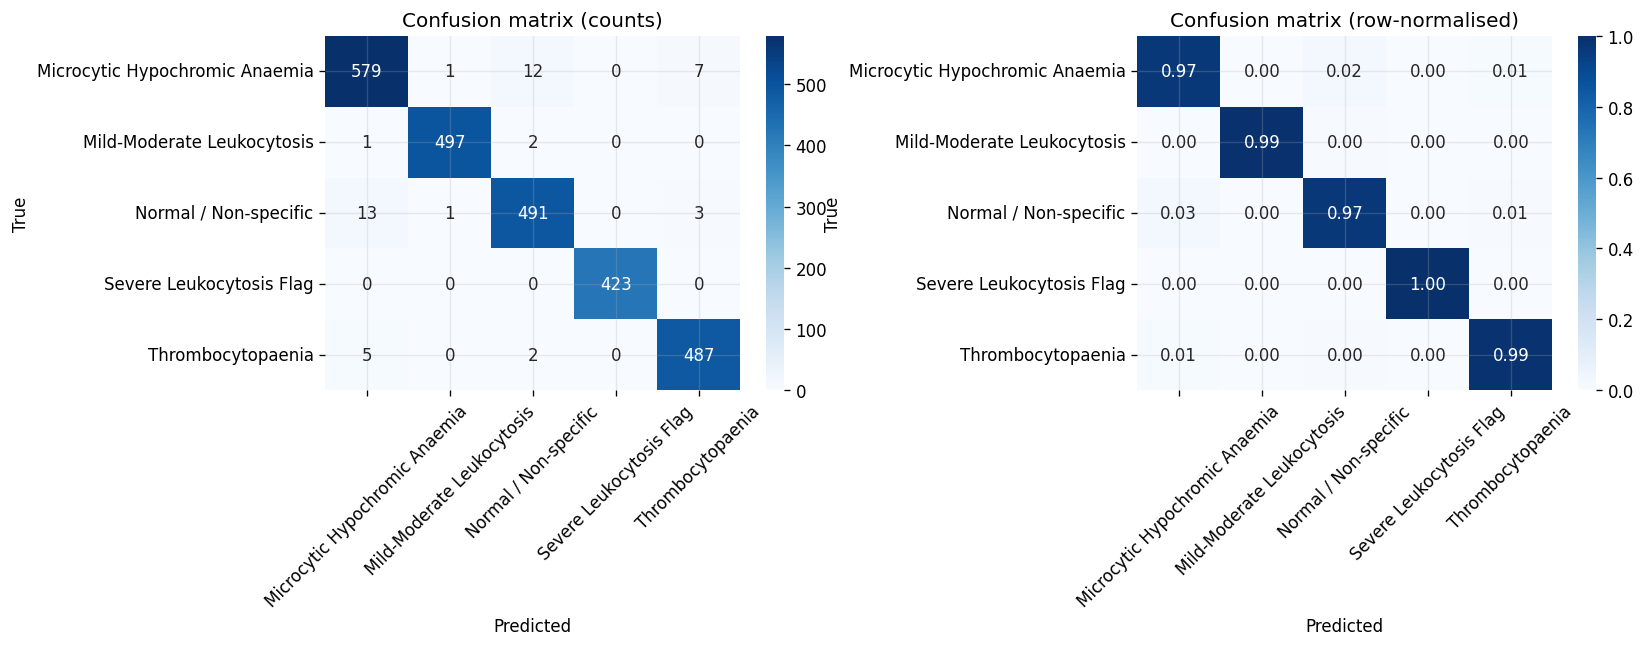

In [30]:
# ---- Confusion matrix ----
from sklearn.metrics import accuracy_score
cm = confusion_matrix(y_test, test_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True"); axes[0].tick_params(axis="x", rotation=45)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[1])
axes[1].set_title("Confusion matrix (row-normalised)"); axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True"); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Fig_confusion_matrix.png"), bbox_inches="tight"); plt.show()

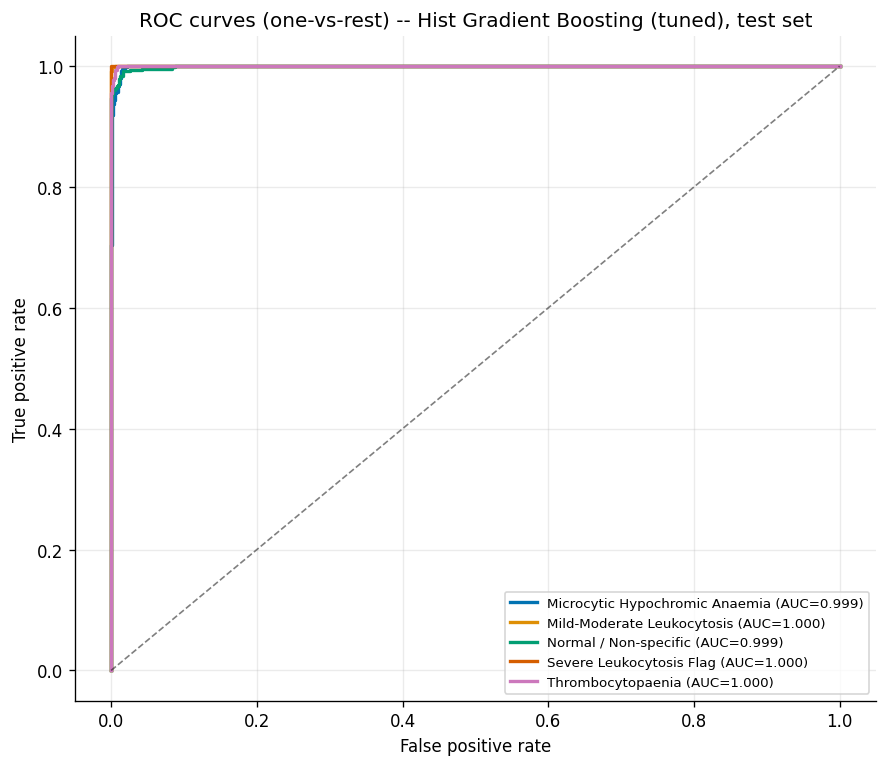

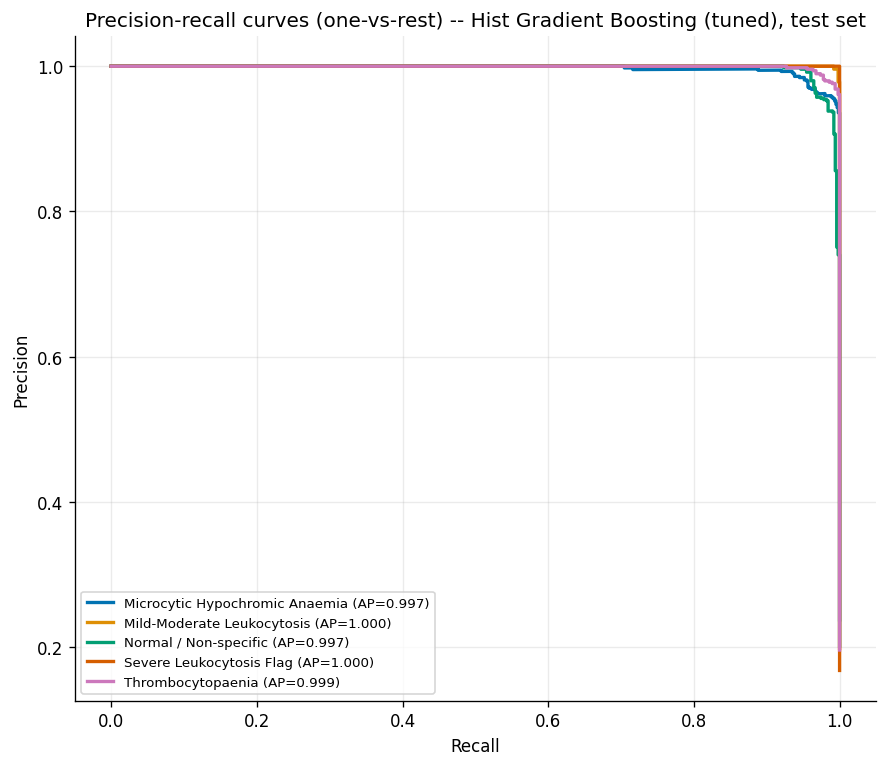

,Class,Average_Precision
0,Severe Leukocytosis Flag,1.0000
1,Mild-Moderate Leukocytosis,0.9999
2,Thrombocytopaenia,0.9992
3,Normal / Non-specific,0.9970
4,Microcytic Hypochromic Anaemia,0.9969
5,Macro_average,0.9986


In [31]:
# ---- ROC and precision-recall curves ----
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

y_test_bin = label_binarize(y_test, classes=list(range(N_CLASSES)))

plt.figure(figsize=(7.5, 6.5))
for i, cls_name in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], test_probs[:, i])
    plt.plot(fpr, tpr, lw=2, label=f"{cls_name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title(f"ROC curves (one-vs-rest) -- {BEST_MODEL_NAME}, test set")
plt.legend(loc="lower right", fontsize=8)
plt.savefig(os.path.join(FIG_DIR, "Fig_roc_curves.png"), bbox_inches="tight"); plt.show()

plt.figure(figsize=(7.5, 6.5))
ap_rows = []
for i, cls_name in enumerate(CLASS_NAMES):
    precision, recall, _ = precision_recall_curve(y_test_bin[:, i], test_probs[:, i])
    ap = average_precision_score(y_test_bin[:, i], test_probs[:, i])
    ap_rows.append({"Class": cls_name, "Average_Precision": round(ap, 4)})
    plt.plot(recall, precision, lw=2, label=f"{cls_name} (AP={ap:.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title(f"Precision-recall curves (one-vs-rest) -- {BEST_MODEL_NAME}, test set")
plt.legend(loc="lower left", fontsize=8)
plt.savefig(os.path.join(FIG_DIR, "Fig_pr_curves.png"), bbox_inches="tight", dpi=300); plt.show()

pr_df = pd.DataFrame(ap_rows).sort_values("Average_Precision", ascending=False).reset_index(drop=True)
pr_df.loc[len(pr_df)] = ["Macro_average", pr_df["Average_Precision"].mean()]
pr_df.to_csv(os.path.join(TAB_DIR, "Table5b_average_precision_per_class.csv"), index=False)
pr_df

## 14. Sensitivity Analysis: Contribution of WBC and WBC-Derived Features

Section 2.7 found that a single feature (WBC) separates one class almost perfectly, which is consistent with
that class following a threshold-based definition on WBC. To assess how much of the final model's performance on
that class depends on WBC specifically, the model is retrained and re-evaluated, on the same split and pipeline,
first with the raw `WBC` column removed, and then with the entire family of features that encode WBC magnitude
removed (identified in Section 2.6: absolute differential counts and any WBC-based ratio, plus any feature with
training-fold correlation above 0.90 with WBC).

In [32]:
WBC_CORR_THRESHOLD = 0.90
NAME_TAGS = ["ANC", "ALC", "AMC", "AEC", "ABC", "_WBC_", "WBC_ratio", "ESR_WBC"] + ABS_DIFF

def wbc_family(feature_names):
    if "WBC" not in feature_names:
        return []
    name_hits = [c for c in feature_names if c != "WBC" and any(tag in c for tag in NAME_TAGS)]
    numeric_train = X_train[feature_names].select_dtypes(include=[np.number])
    corr_hits = []
    if "WBC" in numeric_train.columns:
        tc = numeric_train.drop(columns=["WBC"]).corrwith(numeric_train["WBC"]).abs()
        corr_hits = tc[tc > WBC_CORR_THRESHOLD].index.tolist()
    return sorted(set(["WBC"] + name_hits + corr_hits))

def refit_and_evaluate(drop_features, tag):
    remaining = [c for c in FEATURE_NAMES if c not in drop_features]
    assert len(remaining) >= 3, f"Too few features remain after removing {drop_features}."
    Xtr_d, Xte_d = X_train[remaining], X_test[remaining]
    if not is_dl_best:
        model = clone(final_model_obj)
        pipe = make_full_pipeline(model, feature_names=remaining, use_smote=True)
        pipe.fit(Xtr_d, y_train)
        preds, probs = pipe.predict(Xte_d), pipe.predict_proba(Xte_d)
    else:
        prep = make_preprocessor(remaining)
        Xtr_p, Xte_p = prep.fit_transform(Xtr_d), prep.transform(Xte_d)
        Xtr_b, ytr_b = SMOTE(random_state=SEED, k_neighbors=5).fit_resample(Xtr_p, y_train)
        tl, vl = to_loader(Xtr_b, ytr_b), to_loader(Xte_p, y_test, shuffle=False)
        arch = TabularResNet if "ResNet" in BEST_MODEL_NAME else FTTransformer
        if BEST_MODEL_NAME == "TabNet":
            m = TabNetClassifier(n_d=32, n_a=32, n_steps=5, gamma=1.5, seed=SEED, verbose=0)
            m.fit(Xtr_b, ytr_b, max_epochs=150 if not FAST_DEBUG else 5, patience=15, batch_size=256, virtual_batch_size=64)
            probs = m.predict_proba(Xte_p)
        else:
            m = arch(Xtr_b.shape[1], N_CLASSES)
            m, _ = train_torch_model(m, tl, vl, name=f"{BEST_MODEL_NAME}-{tag}")
            m.eval()
            with torch.no_grad():
                probs = F.softmax(m(torch.tensor(Xte_p, dtype=torch.float32).to(device)), dim=1).cpu().numpy()
        preds = probs.argmax(1)
    report = classification_report(y_test, preds, target_names=CLASS_NAMES, output_dict=True)
    metrics = {"Accuracy": accuracy_score(y_test, preds), "MacroF1": f1_score(y_test, preds, average="macro"),
               "ROC_AUC": roc_auc_score(y_test, probs, average="macro", multi_class="ovr")}
    return report, metrics

from sklearn.base import clone
WBC_FAMILY = wbc_family(FEATURE_NAMES)
print(f"WBC-correlated feature family ({len(WBC_FAMILY)} of {len(FEATURE_NAMES)} features): {WBC_FAMILY}")

report_wbc_only, metrics_wbc_only   = refit_and_evaluate(["WBC"], "no-wbc")
report_wbc_family, metrics_wbc_fam  = refit_and_evaluate(WBC_FAMILY, "no-wbc-family")

print(f"\nFull-feature model      -- Accuracy={final_accuracy:.4f}  Macro-F1={final_macro_f1:.4f}  ROC-AUC={final_roc_auc:.4f}")
print(f"WBC removed             -- Accuracy={metrics_wbc_only['Accuracy']:.4f}  Macro-F1={metrics_wbc_only['MacroF1']:.4f}  ROC-AUC={metrics_wbc_only['ROC_AUC']:.4f}")
print(f"WBC family removed      -- Accuracy={metrics_wbc_fam['Accuracy']:.4f}  Macro-F1={metrics_wbc_fam['MacroF1']:.4f}  ROC-AUC={metrics_wbc_fam['ROC_AUC']:.4f}")

comparison_df = pd.DataFrame([
    {"Class": c, "F1_full_features": round(report_dict[c]["f1-score"], 4),
     "F1_WBC_removed": round(report_wbc_only[c]["f1-score"], 4),
     "F1_WBC_family_removed": round(report_wbc_family[c]["f1-score"], 4)}
    for c in CLASS_NAMES
])
comparison_df["Delta_family_vs_full"] = (comparison_df["F1_WBC_family_removed"] - comparison_df["F1_full_features"]).round(4)
comparison_df.to_csv(os.path.join(TAB_DIR, "Table5c_WBC_sensitivity_by_class.csv"), index=False)
comparison_df

WBC-correlated feature family (6 of 23 features): ['Basophil count', 'Eosinophil count', 'Lymphocyte count', 'Monocyte count', 'Neutrophil count', 'WBC']

Full-feature model      -- Accuracy=0.9814  Macro-F1=0.9825  ROC-AUC=0.9996
WBC removed             -- Accuracy=0.9735  Macro-F1=0.9743  ROC-AUC=0.9994
WBC family removed      -- Accuracy=0.8249  Macro-F1=0.8124  ROC-AUC=0.9635


,Class,F1_full_features,F1_WBC_removed,F1_WBC_family_removed,Delta_family_vs_full
0,Microcytic Hypochromic Anaemia,0.9674,0.9683,0.9417,-0.0257
1,Mild-Moderate Leukocytosis,0.9950,0.9772,0.7701,-0.2249
2,Normal / Non-specific,0.9675,0.9512,0.7552,-0.2123
3,Severe Leukocytosis Flag,1.0000,0.9941,0.6692,-0.3308
4,Thrombocytopaenia,0.9828,0.9808,0.9257,-0.0571


**Interpretation.** If the flagged class's performance change, once the entire WBC-correlated family is removed,
is no larger than the change seen for other classes, this indicates that the class remains separable from
information distributed across several correlated CBC parameters rather than from a single engineered shortcut,
and that the preprocessing pipeline does not leak information through any other route. The magnitude of the
change is reported in Table 5c and should be interpreted alongside Section 2.7, without treating either result
in isolation.

## 15. Interpretable Reference Model

To make the benefit of the selected model transparent, a single shallow decision tree (fixed maximum depth) is
fitted on the same training split and evaluated on the same test set. Comparing its performance with Table 5
shows how much of the classification task a simple, fully inspectable rule set already captures, and how much
additional performance the more complex model contributes.

In [33]:
from sklearn.tree import DecisionTreeClassifier, export_text

shallow_tree = DecisionTreeClassifier(max_depth=4, random_state=SEED)
shallow_pipe = make_full_pipeline(shallow_tree, use_smote=True)
shallow_pipe.fit(X_train, y_train)
shallow_preds = shallow_pipe.predict(X_test)

shallow_metrics = {"Model": "Shallow Decision Tree (depth=4)",
                    "Accuracy": accuracy_score(y_test, shallow_preds), "MacroF1": f1_score(y_test, shallow_preds, average="macro"),
                    "WeightedF1": f1_score(y_test, shallow_preds, average="weighted")}
best_metrics = {"Model": BEST_MODEL_NAME, "Accuracy": final_accuracy, "MacroF1": final_macro_f1, "WeightedF1": final_weighted_f1}
baseline_comparison_df = pd.DataFrame([shallow_metrics, best_metrics])
baseline_comparison_df.to_csv(os.path.join(TAB_DIR, "Table5d_interpretable_baseline_comparison.csv"), index=False)
print("A depth-4 decision tree, fully readable as a short set of threshold rules, already reaches the "
      "macro-F1 below; the gap to the selected model quantifies the benefit of the additional complexity.")
baseline_comparison_df

A depth-4 decision tree, fully readable as a short set of threshold rules, already reaches the macro-F1 below; the gap to the selected model quantifies the benefit of the additional complexity.


,Model,Accuracy,MacroF1,WeightedF1
0,Shallow Decision Tree (depth=4),0.955626,0.956428,0.955098
1,Hist Gradient Boosting (tuned),0.981379,0.982549,0.981375


## 16. Bootstrap Confidence Intervals for the Test-Set Metrics

In [34]:
rng = np.random.default_rng(SEED)
boot_acc, boot_f1, boot_auc = [], [], []
y_test_arr = np.asarray(y_test)
n = len(y_test_arr)
for _ in range(N_BOOT):
    idx = rng.integers(0, n, n)
    yb, pb, prb = y_test_arr[idx], test_preds[idx], test_probs[idx]
    boot_acc.append(accuracy_score(yb, pb))
    boot_f1.append(f1_score(yb, pb, average="macro"))
    try:
        boot_auc.append(roc_auc_score(yb, prb, average="macro", multi_class="ovr"))
    except ValueError:
        pass

def ci(arr):
    return np.percentile(arr, [2.5, 97.5])

bootstrap_summary = pd.DataFrame({"Metric": ["Accuracy", "Macro-F1", "ROC-AUC (OVR)"],
    "Point_estimate": [final_accuracy, final_macro_f1, final_roc_auc],
    "95%_CI_low": [ci(boot_acc)[0], ci(boot_f1)[0], ci(boot_auc)[0]],
    "95%_CI_high": [ci(boot_acc)[1], ci(boot_f1)[1], ci(boot_auc)[1]]}).round(4)
bootstrap_summary.to_csv(os.path.join(TAB_DIR, "Table6_bootstrap_CI.csv"), index=False)
bootstrap_summary

,Metric,Point_estimate,95%_CI_low,95%_CI_high
0,Accuracy,0.9814,0.9758,0.9865
1,Macro-F1,0.9825,0.9774,0.9873
2,ROC-AUC (OVR),0.9996,0.9994,0.9998


## 17. Probability Calibration on the Test Set

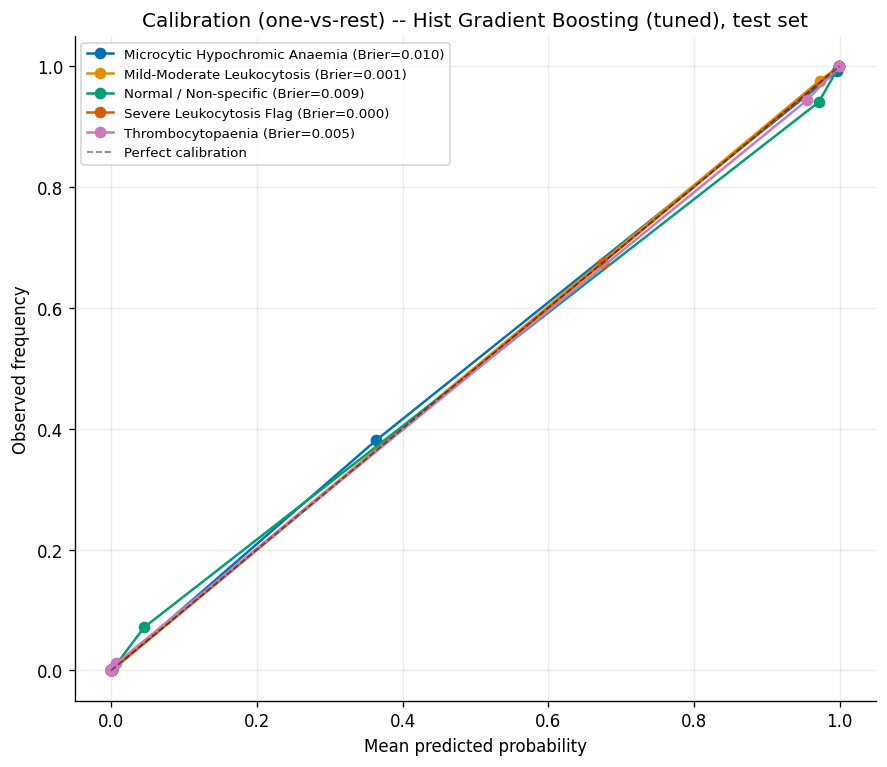

,Class,Brier_score
0,Severe Leukocytosis Flag,0.00000
1,Mild-Moderate Leukocytosis,0.00120
2,Thrombocytopaenia,0.00510
3,Normal / Non-specific,0.00870
4,Microcytic Hypochromic Anaemia,0.01030
5,Macro_average,0.00506


In [35]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

plt.figure(figsize=(7.5, 6.5))
brier_rows = []
for i, cls_name in enumerate(CLASS_NAMES):
    frac_pos, mean_pred = calibration_curve(y_test_bin[:, i], test_probs[:, i], n_bins=10, strategy="quantile")
    brier = brier_score_loss(y_test_bin[:, i], test_probs[:, i])
    brier_rows.append({"Class": cls_name, "Brier_score": round(brier, 4)})
    plt.plot(mean_pred, frac_pos, "o-", lw=1.5, label=f"{cls_name} (Brier={brier:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="Perfect calibration")
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed frequency")
plt.title(f"Calibration (one-vs-rest) -- {BEST_MODEL_NAME}, test set")
plt.legend(loc="upper left", fontsize=8)
plt.savefig(os.path.join(FIG_DIR, "Fig_calibration_curves.png"), bbox_inches="tight", dpi=300); plt.show()

brier_df = pd.DataFrame(brier_rows).sort_values("Brier_score").reset_index(drop=True)
brier_df.loc[len(brier_df)] = ["Macro_average", brier_df["Brier_score"].mean()]
brier_df.to_csv(os.path.join(TAB_DIR, "Table5e_brier_scores.csv"), index=False)
brier_df

## 18. Learning Curves

For computational efficiency, the number of cross-validation folds and training-size points used here is reduced
whenever the selected model is itself an ensemble of several tuned models (the stacking ensemble refits every
base learner at every point on the curve, multiplying the cost accordingly); a single tuned model uses the
full five-fold, six-point setting.

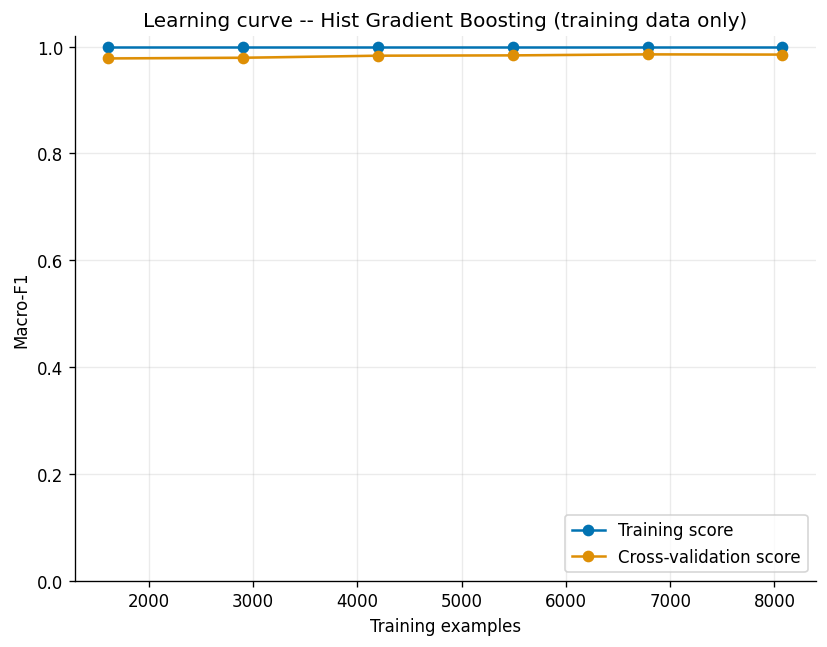

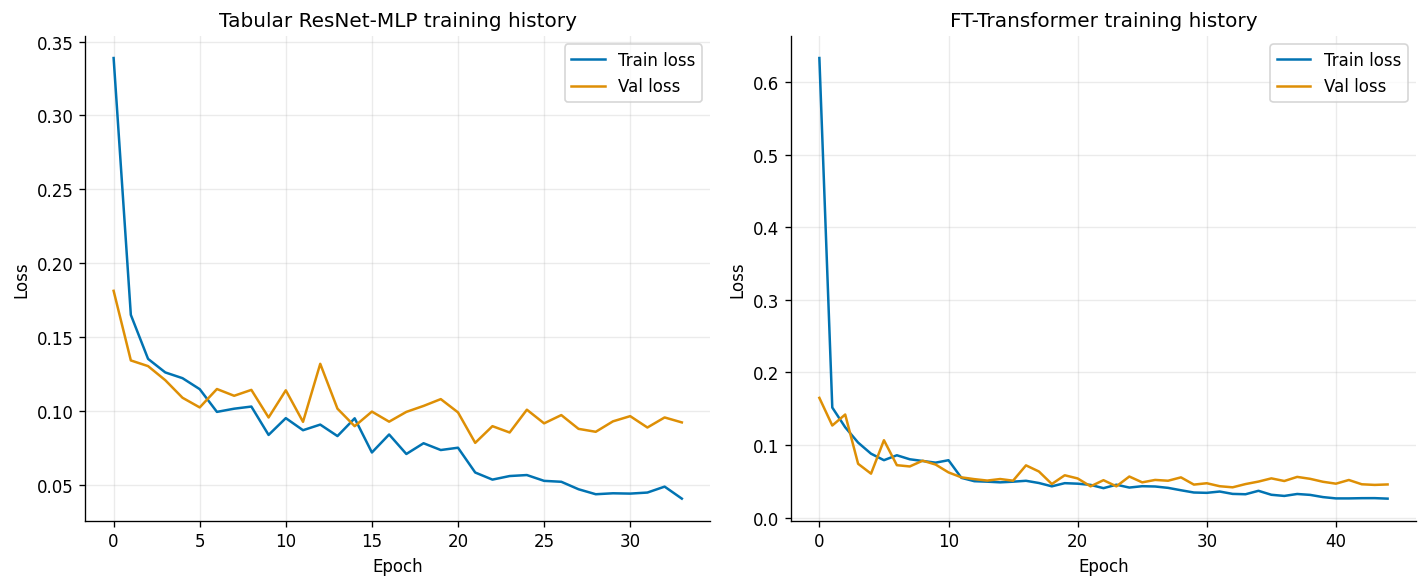

In [36]:
from sklearn.model_selection import learning_curve

def plot_learning_curve(estimator, X, y, title, fname, cv, n_sizes):
    train_sizes, train_scores, val_scores = learning_curve(estimator, X, y, cv=cv, scoring=make_scorer(f1_score, average="macro"),
                                                            train_sizes=np.linspace(0.2, 1.0, n_sizes), n_jobs=-1, shuffle=True, random_state=SEED)
    train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)
    plt.figure(figsize=(7, 5.5))
    plt.plot(train_sizes, train_mean, "o-", label="Training score"); plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
    plt.plot(train_sizes, val_mean, "o-", label="Cross-validation score"); plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
    plt.xlabel("Training examples"); plt.ylabel("Macro-F1"); plt.title(title); plt.legend(loc="lower right"); plt.ylim(0.0, 1.02)
    plt.savefig(os.path.join(FIG_DIR, fname), bbox_inches="tight"); plt.show()

lc_model = tuned_models.get(clean_best_name, BASE_MODELS.get(clean_best_name))
if lc_model is not None:
    is_ensemble_of_tuned = (BEST_MODEL_NAME == HYBRID_NAME)
    lc_cv    = StratifiedKFold(n_splits=3 if is_ensemble_of_tuned else 5, shuffle=True, random_state=SEED)
    lc_sizes = 4 if is_ensemble_of_tuned else 6
    plot_learning_curve(make_full_pipeline(lc_model, use_smote=True), X_train, y_train,
                        f"Learning curve -- {clean_best_name} (training data only)", "Fig_learning_curve.png",
                        cv=lc_cv, n_sizes=lc_sizes)
else:
    print("Selected model is a deep-learning architecture; see the training/validation loss curves below instead.")

if TORCH_OK and dl_histories:
    fig, axes = plt.subplots(1, len(dl_histories), figsize=(6 * len(dl_histories), 5), squeeze=False)
    for i, (name, hist) in enumerate(dl_histories.items()):
        ax = axes[0][i]
        ax.plot(hist["train_loss"], label="Train loss"); ax.plot(hist["val_loss"], label="Val loss")
        ax.set_title(f"{name} training history"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.legend()
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Fig_dl_training_history.png"), bbox_inches="tight"); plt.show()

## 19. McNemar Test on the Two Top-Ranked Models

The Friedman/Nemenyi comparison in Section 11 uses training-data cross-validation and was the basis for model
selection. As a complementary, independent check, a McNemar test compares the actual test-set predictions of the
two top-ranked candidates from the leaderboard. This is the only place a pairwise statistical comparison is
computed from the test set, and it is used to characterise the result, not to choose between models.

In [37]:
from statsmodels.stats.contingency_tables import mcnemar

top2 = leaderboard.head(2)["Model"].tolist()

def get_test_preds_for(model_name):
    clean = model_name.replace(" (tuned)", "")
    if model_name == BEST_MODEL_NAME:
        return test_preds
    if is_dl_best and clean in (dl_results if TORCH_OK else {}):
        return None  # not needed: BEST_MODEL_NAME already covers the DL case above
    m = tuned_models.get(clean, BASE_MODELS.get(clean))
    if m is None:
        return None
    p = make_full_pipeline(m, use_smote=True); p.fit(X_train, y_train)
    return p.predict(X_test)

preds_a = get_test_preds_for(top2[0])
preds_b = get_test_preds_for(top2[1]) if len(top2) > 1 else None
if preds_a is not None and preds_b is not None:
    correct_a, correct_b = (preds_a == y_test), (preds_b == y_test)
    b01 = int((correct_a & ~correct_b).sum()); b10 = int((~correct_a & correct_b).sum())
    result = mcnemar([[0, b01], [b10, 0]], exact=(b01 + b10 < 25))
    print(f"McNemar test, {top2[0]} vs {top2[1]}: statistic={result.statistic:.4f}, p={result.pvalue:.4g}")
    pd.DataFrame([{"Model_A": top2[0], "Model_B": top2[1], "statistic": result.statistic, "p_value": result.pvalue}]) \
        .to_csv(os.path.join(TAB_DIR, "Table8_mcnemar_test.csv"), index=False)

McNemar test, Hist Gradient Boosting (tuned) vs Stacking Ensemble: statistic=5.0000, p=0.424


## 20. Feature Importance

SHAP values are computed for the selected model when it is tree-based; TabNet's built-in attention-based
importances are reported if TabNet is selected. Permutation importance (model-agnostic, computed once on the
test set after model selection was finalised) is reported for every model type as a cross-check. The number of
permutation repeats is reduced for the stacking ensemble, which requires calling every base learner on every
repeat.

<Figure size 768x576 with 0 Axes>

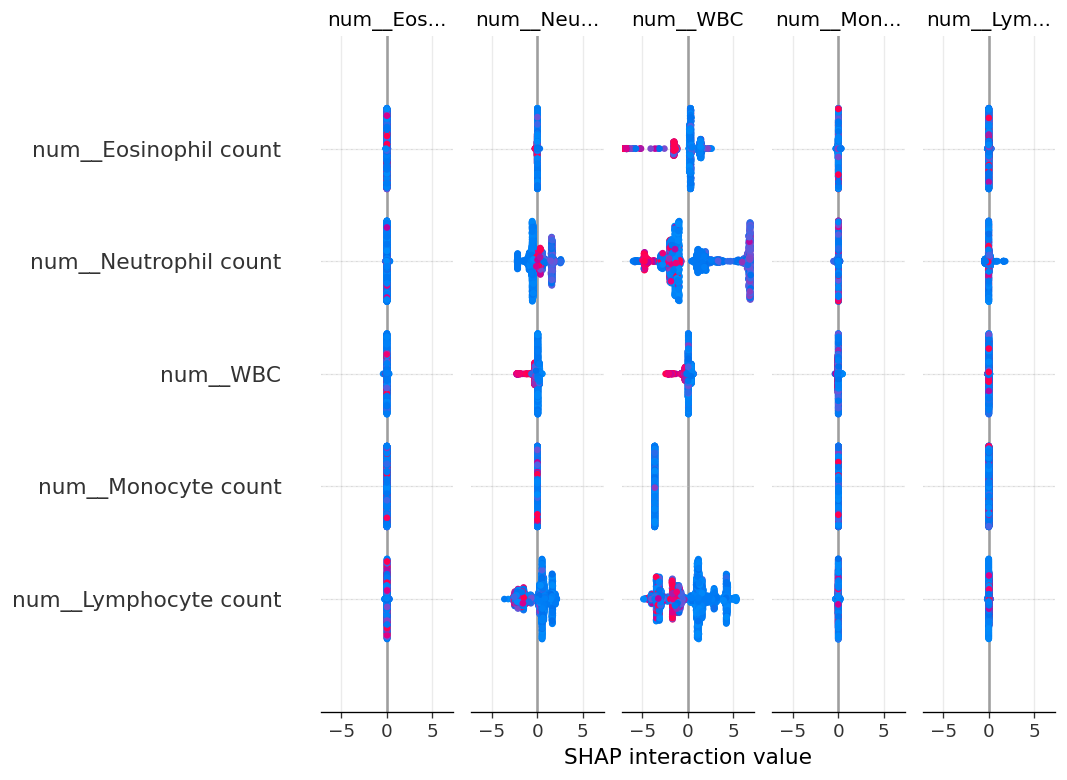

In [38]:
TREE_MODELS = {"LightGBM", "XGBoost", "CatBoost", "Random Forest", "Extra Trees", "Gradient Boosting",
               "Hist Gradient Boosting", "Decision Tree", "Bagging", "AdaBoost"}

if not is_dl_best and clean_best_name in TREE_MODELS:
    import shap
    preproc_fitted = final_pipe.named_steps["preprocess"]
    X_sample = preproc_fitted.transform(X_train.sample(min(2000, len(X_train)), random_state=SEED))
    feature_names_out = preproc_fitted.get_feature_names_out()
    explainer = shap.TreeExplainer(final_pipe.named_steps["model"])
    shap_values = explainer.shap_values(X_sample)
    plt.figure()
    if isinstance(shap_values, list):
        shap.summary_plot(shap_values, X_sample, feature_names=feature_names_out, class_names=CLASS_NAMES, show=False)
    else:
        shap.summary_plot(shap_values, X_sample, feature_names=feature_names_out, show=False)
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Fig_shap_summary.png"), bbox_inches="tight"); plt.show()
elif is_dl_best and BEST_MODEL_NAME == "TabNet":
    tabnet_importances = pd.Series(final_model_obj.feature_importances_, index=final_preprocessor.get_feature_names_out()).sort_values(ascending=False)
    tabnet_importances.to_frame("Importance").to_csv(os.path.join(TAB_DIR, "Table9_tabnet_feature_importance.csv"))
    top_n = min(20, len(tabnet_importances))
    plt.figure(figsize=(8, max(4, 0.35 * top_n)))
    tabnet_importances.head(top_n).sort_values().plot(kind="barh", color="#4C72B0")
    plt.xlabel("TabNet feature importance"); plt.title(f"TabNet feature importance -- top {top_n}")
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Fig_tabnet_feature_importance.png"), bbox_inches="tight", dpi=300); plt.show()
else:
    print("Selected model is not a tree model or TabNet; see the permutation importance below, which applies to any model type.")

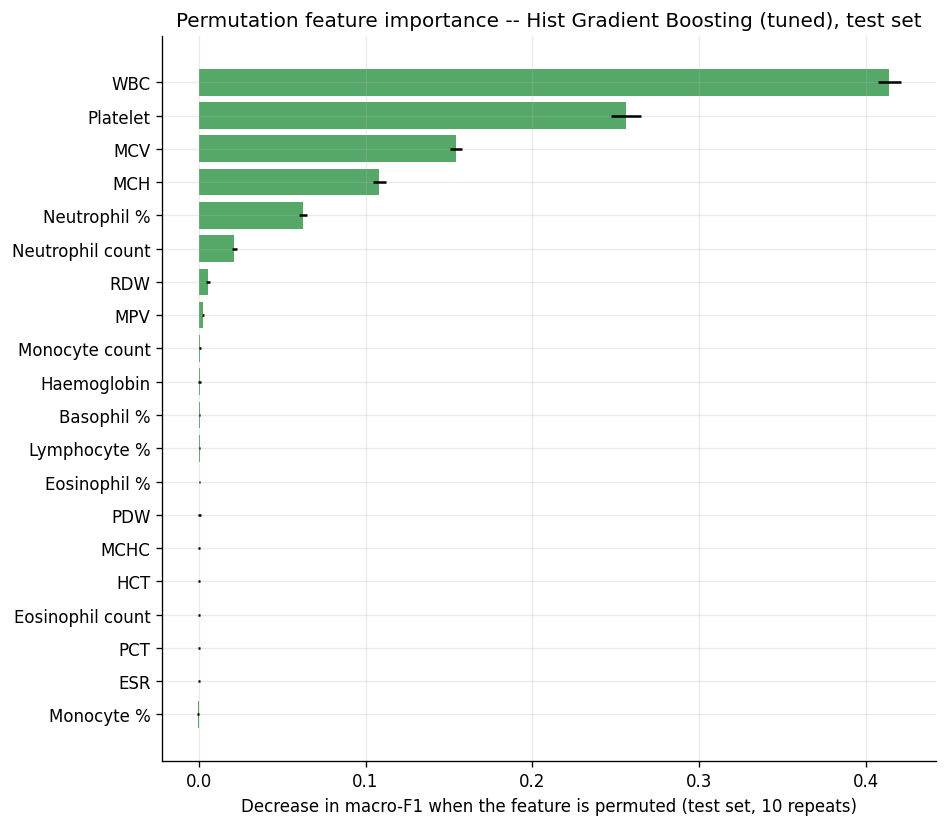

,Feature,Perm_Importance_mean,Perm_Importance_std
0,WBC,0.414161,0.006977
1,Platelet,0.256217,0.008869
2,MCV,0.154336,0.003808
3,MCH,0.108385,0.004124
4,Neutrophil %,0.062426,0.002279
5,Neutrophil count,0.021339,0.001534
6,RDW,0.005481,0.001079
7,MPV,0.002473,0.000738
8,Monocyte count,0.000881,0.000716
9,Haemoglobin,0.000648,0.000904


In [39]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.inspection import permutation_importance

class RawFeatureWrapper(BaseEstimator, ClassifierMixin):
    """Uniform predict/predict_proba over the original feature columns, regardless of whether the fitted
    model is the sklearn/imblearn pipeline, a PyTorch model, or TabNet. Lets sklearn.inspection tools run
    on any final model type without changing Sections 10-13 above."""
    def __init__(self, kind, obj, preprocessor=None):
        self.kind, self.obj, self.preprocessor = kind, obj, preprocessor
        self.classes_ = np.arange(N_CLASSES)
    def fit(self, X, y=None): return self
    def predict_proba(self, X):
        if self.kind == "sklearn_pipeline":
            return self.obj.predict_proba(X)
        X_proc = self.preprocessor.transform(X)
        if self.kind == "tabnet":
            return self.obj.predict_proba(X_proc)
        with torch.no_grad():
            return F.softmax(self.obj(torch.tensor(X_proc, dtype=torch.float32).to(device)), dim=1).cpu().numpy()
    def predict(self, X): return self.predict_proba(X).argmax(axis=1)

if not is_dl_best:
    wrapped_model = RawFeatureWrapper("sklearn_pipeline", final_pipe)
elif clean_best_name == "TabNet":
    wrapped_model = RawFeatureWrapper("tabnet", final_model_obj, final_preprocessor)
else:
    wrapped_model = RawFeatureWrapper("torch", final_model_obj, final_preprocessor)

perm_repeats = 5 if BEST_MODEL_NAME == HYBRID_NAME else 10
perm_result = permutation_importance(wrapped_model, X_test, y_test, scoring="f1_macro", n_repeats=perm_repeats, random_state=SEED, n_jobs=1)
perm_df = pd.DataFrame({"Feature": X_test.columns, "Perm_Importance_mean": perm_result.importances_mean,
                        "Perm_Importance_std": perm_result.importances_std}).sort_values("Perm_Importance_mean", ascending=False).reset_index(drop=True)
perm_df.to_csv(os.path.join(TAB_DIR, "Table10_permutation_importance.csv"), index=False)

top_n = min(20, len(perm_df))
plt.figure(figsize=(8, max(4, 0.35 * top_n)))
plt.barh(perm_df["Feature"].head(top_n)[::-1], perm_df["Perm_Importance_mean"].head(top_n)[::-1],
         xerr=perm_df["Perm_Importance_std"].head(top_n)[::-1], color="#55A868")
plt.xlabel(f"Decrease in macro-F1 when the feature is permuted (test set, {perm_repeats} repeats)")
plt.title(f"Permutation feature importance -- {BEST_MODEL_NAME}, test set")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Fig_permutation_importance.png"), bbox_inches="tight", dpi=300); plt.show()
perm_df.head(15)

## 21. Final Leaderboard Figure

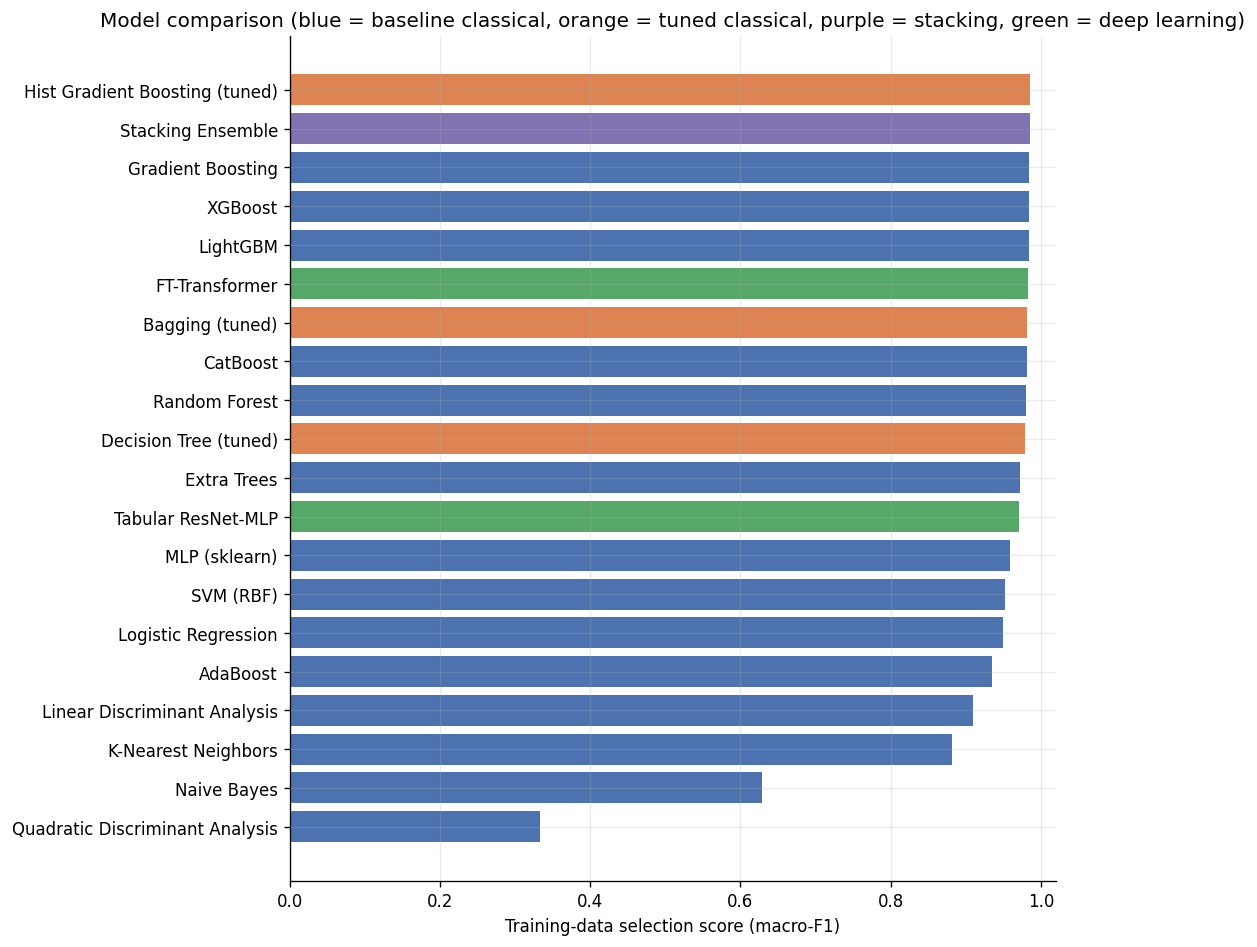

In [40]:
fig, ax = plt.subplots(figsize=(9, 8))
plot_df = leaderboard.sort_values("Selection_Score_MacroF1")
colors = ["#4C72B0" if "tuned" not in m and m not in (dl_results.keys() if TORCH_OK else []) and m != HYBRID_NAME else
          ("#DD8452" if "tuned" in m else ("#8172B2" if m == HYBRID_NAME else "#55A868")) for m in plot_df["Model"]]
ax.barh(plot_df["Model"], plot_df["Selection_Score_MacroF1"], color=colors)
ax.set_xlabel("Training-data selection score (macro-F1)")
ax.set_title("Model comparison (blue = baseline classical, orange = tuned classical, purple = stacking, green = deep learning)")
ax.set_xlim(0, 1.02)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "Fig_model_leaderboard.png"), bbox_inches="tight"); plt.show()

## 22. Export

In [41]:
import shutil
zip_path = shutil.make_archive(os.path.join(os.path.dirname(OUT_DIR), "paper_outputs"), "zip", OUT_DIR)
print("All outputs zipped to:", zip_path)
print("\nFiles generated:")
for root, _, files in os.walk(OUT_DIR):
    for f in sorted(files):
        print(os.path.join(root, f).replace(OUT_DIR + os.sep, ""))

All outputs zipped to: /kaggle/working/paper_outputs.zip

Files generated:
figures/Fig_calibration_curves.png
figures/Fig_confusion_matrix.png
figures/Fig_dl_training_history.png
figures/Fig_learning_curve.png
figures/Fig_model_leaderboard.png
figures/Fig_permutation_importance.png
figures/Fig_pr_curves.png
figures/Fig_roc_curves.png
figures/Fig_shap_summary.png
tables/Table10_permutation_importance.csv
tables/Table1_class_distribution.csv
tables/Table2_CV_model_screening.csv
tables/Table2b_stacking_cv.csv
tables/Table2c_repeated_cv_stability.csv
tables/Table2d_tuned_model_cv.csv
tables/Table3_DL_validation_scores.csv
tables/Table4_unified_leaderboard.csv
tables/Table5_test_classification_report.csv
tables/Table5b_average_precision_per_class.csv
tables/Table5c_WBC_sensitivity_by_class.csv
tables/Table5d_interpretable_baseline_comparison.csv
tables/Table5e_brier_scores.csv
tables/Table6_bootstrap_CI.csv
tables/Table7_friedman_test.csv
tables/Table8_mcnemar_test.csv
tables/TableS2_missin

In [42]:
print("Results summary")
print(f"Selected model (training-data evidence only): {BEST_MODEL_NAME}")
print(f"Held-out test performance (n={len(y_test)}):")
print(f"  Accuracy    : {final_accuracy:.4f}  (95% CI: {ci(boot_acc)[0]:.4f}-{ci(boot_acc)[1]:.4f})")
print(f"  Macro-F1    : {final_macro_f1:.4f}  (95% CI: {ci(boot_f1)[0]:.4f}-{ci(boot_f1)[1]:.4f})")
print(f"  Weighted-F1 : {final_weighted_f1:.4f}")
print(f"  ROC-AUC(OVR): {final_roc_auc:.4f}  (95% CI: {ci(boot_auc)[0]:.4f}-{ci(boot_auc)[1]:.4f})")
print(f"Friedman test across {len(model_order)} model candidates (training-data CV): chi2={stat:.3f}, p={friedman_p:.4g}")

Results summary
Selected model (training-data evidence only): Hist Gradient Boosting (tuned)
Held-out test performance (n=2524):
  Accuracy    : 0.9814  (95% CI: 0.9758-0.9865)
  Macro-F1    : 0.9825  (95% CI: 0.9774-0.9873)
  Weighted-F1 : 0.9814
  ROC-AUC(OVR): 0.9996  (95% CI: 0.9994-0.9998)
Friedman test across 18 model candidates (training-data CV): chi2=81.884, p=1.771e-10


## 23. Manuscript End-Matter Checklist

Fill in every placeholder before submission.

**Ethics declarations.** State the approving Institutional Review Board / Ethics Committee name and approval or
reference number, whether informed consent was obtained or formally waived (and by whom), and confirm that the
data were de-identified before analysis, including who performed and validated the class-label assignment.
`[ethics committee name + approval number]`

**Data availability.** State where the dataset (or a de-identified/synthetic surrogate, if the raw data cannot be
shared) can be accessed — a repository name and DOI/accession number, or the conditions under which it is
available on reasonable request. `[repository/DOI or access statement]`

**Code availability.** State the repository URL and licence for this notebook and its outputs.
`[repository URL] / [licence]`

**Author contributions, competing interests, acknowledgements.** Fill in per journal requirements.

**Limitations paragraph — points to cover, based on this notebook's analyses:**
- The class labels are CBC-pattern categories (Section 2); one class is separable from a single feature at
  near-perfect AUC (Section 2.7), consistent with a threshold-based definition for that class.
- Table 5c reports how the model's performance on that class changes once WBC and WBC-correlated features are
  removed, alongside the same comparison for the other classes.
- The deep models are compared to the classical models using a single validation split rather than full
  cross-validation (Section 10), a weaker but standard estimate for that model class.
- Report the study population and setting (retrospective/prospective, single/multi-centre) and any inclusion or
  exclusion criteria applied before this dataset was assembled, so that the generalisability of the reported
  metrics is clear to the reader.